# Extension: the Cryptocurrency Futures Pressure Index (CFPI)

In this notebook I clean the CFTC Traders in Financial Futures reports for the CME Bitcoin and Ether contracts, build the three futures variables (asset manager positioning P, the futures basis B and open-interest growth C), combine them into the CFPI with rolling PCA, and run the predictive regressions. The momentum-adjusted versions of the index are constructed in `cfpi_variants.py`.

Run order: 01 → this notebook → cfpi_variants.py.

## The setup cell

Imports, paths and every choice I made for the extension in one config.

In [2]:
from pathlib import Path
import re
import warnings
import importlib.util
import subprocess
import sys

import numpy as np
import pandas as pd
import statsmodels.api as sm

# Only for the diagnostic plot
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 140)
pd.set_option("display.width", 180)

# The directories
# On my machine this notebook sits in FI-thesis-template and the CFTC folder is one level up,
# so I check both places Jupyter could be started from
CWD = Path.cwd().resolve()

if (CWD / "Dataset" / "Dataset.csv").exists() and (CWD.parent / "CFTC").exists():
    THESIS_DIR = CWD
    PROJECT_ROOT = CWD.parent
elif (CWD / "FI-thesis-template" / "Dataset" / "Dataset.csv").exists() and (CWD / "CFTC").exists():
    PROJECT_ROOT = CWD
    THESIS_DIR = CWD / "FI-thesis-template"
else:
    raise FileNotFoundError(
        "Could not locate both FI-thesis-template/Dataset/Dataset.csv and CFTC/. "
        "Start Jupyter either from the project root or from FI-thesis-template."
    )

CFTC_DIR = PROJECT_ROOT / "CFTC"
DATASET_PATH = THESIS_DIR / "Dataset" / "Dataset.csv"
BASIS_DEMO_PATH = THESIS_DIR / "References" / "crypto_futures_basis_yahoo.csv"
OUTPUT_DIR = THESIS_DIR / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

CONFIG = {
    # My main empirical choices
    "ASSETS": ["BTC", "ETH"],
    "HORIZONS": [1, 2, 3, 4, 6, 8],
    "RETURN_TYPE": "simple",       # Simple returns, same as in my replication
    "WEEKLY_FREQ": "AUTO_CFTC_WEEKDAY",  # Weeks end on the CFTC position weekday (can be overridden, e.g. "W-SUN")
    "ROLLING_WINDOW": 36,          # In weeks, other windows are in Robustness/
    "EPSILON": 1e-8,
    "KAPPA": 1.0,
    "USE_BTC_ONLY_ROBUSTNESS": False,
    "AUTO_INSTALL_MISSING_PACKAGES": False,  # True lets the notebook pip install xlrd/openpyxl itself

    # HAC lags: None means I use the forecast horizon h
    "HAC_MAXLAGS_BY_HORIZON": {1: None, 2: None, 3: None, 4: None, 6: None, 8: None},

    # Where the inputs are
    "CFTC_DIR": CFTC_DIR,
    "CFTC_FILE_GLOB": "*.xls*",    # One CFTC file per year
    "DATASET_PATH": DATASET_PATH,   # The dataset from 01
    "BASIS_DEMO_PATH": BASIS_DEMO_PATH,  # Short demo file, I don't use it in the main sample

    # Reading the CFTC Excel files
    "CFTC_EXCEL_SHEET": 0,          # The data is on the first sheet

    # Column names in the CFTC files and in Dataset.csv
    # If a file has different labels, I change them here after checking the inspection cells
    "CFTC": {
        "date_col": "report_date_as_mm_dd_yyyy",
        "market_col": "market_and_exchange_names",
        "contract_col": "market_and_exchange_names",
        "am_long_col": "asset_mgr_positions_long_all",
        "am_short_col": "asset_mgr_positions_short_all",
        "open_interest_col": "open_interest_all",
        "price_col": None,          # The CFTC reports don't have prices
    },

    "BASIS": {
        "source": "yahoo_continuous_cme",  # Main spec: continuous CME futures premium from Yahoo
        "date_col": "date",         # Only matters if source="csv"
        "asset_col": "asset",
        "futures_price_col": "futures_close",
        "spot_price_col": "spot_close",
        "maturity_col": "expiry",
        "basis_col": "annualized_basis",
        "contract_col": "ticker",
        "tau_col": "tau_days",
        "min_days_to_maturity": 7,  # Only for the annualized/contract-level versions, not the log premium
        "alignment": "previous",    # Latest basis on or before each CFTC position date
        "previous_tolerance_days": 7,
        "drop_unmatched_cftc_dates": True,
        "yahoo_start": "AUTO_ETH_CFTC_START",
        "yahoo_end": "AUTO_CFTC_END",
        "yahoo_contract_years_after_end": 2,
        "yahoo_cache_file": OUTPUT_DIR / "yahoo_crypto_futures_basis_daily.csv",
        "yahoo_continuous_cache_file": OUTPUT_DIR / "yahoo_crypto_futures_basis_continuous_proxy_daily.csv",
        "yahoo_raw_prices_file": OUTPUT_DIR / "yahoo_crypto_futures_yahoo_prices_raw.csv",
        "yahoo_force_redownload": False,
        "allow_continuous_futures_fallback": True,
        "coverage_grace_days": 45,
        "basis_measure": "log_continuous_futures_premium",  # B_t^j = ln(F_cont,t^j / S_t^j), I don't scale by time to expiry
        "continuous_basis_tau_rule": "not_used_for_log_premium",
        "spot_tickers": {"BTC": "BTC-USD", "ETH": "ETH-USD"},
        "continuous_futures_tickers": {"BTC": "BTC=F", "ETH": "ETH=F"},
        "futures_roots": {"BTC": "BTC", "ETH": "ETH"},
        "month_codes": {1: "F", 2: "G", 3: "H", 4: "J", 5: "K", 6: "M", 7: "N", 8: "Q", 9: "U", 10: "V", 11: "X", 12: "Z"},
        "manual_expiry_overrides": {},  # e.g. {"BTCM26.CME": "2026-06-26"}
        "manual_ticker_overrides": {},  # e.g. {"BTC": {"2026-06": "BTCM26.CME"}}
    },

    "RETURNS_GOOGLE": {
        "date_col": "time",
        "return_col": "cmkt",
        "google_search_col": "bitcoin_search",
        "google_method": "replication",  # Same as Liu and Tsyvinski: search minus its prior 4-week mean, then standardized
        "google_rolling_weeks": 4,

        # CMKT in Dataset.csv stops in 2021, so for the extension I use an equal-weighted BTC/ETH return from Yahoo
        # Everything else stays the same, and the outputs say which return series was used
        "return_source": "yahoo_btc_eth_proxy",  # Other options: "dataset_cmkt", "fill_missing_cmkt_with_yahoo_proxy"
        "yahoo_return_start": "AUTO_ETH_CFTC_START",
        "yahoo_return_end": "AUTO_CFTC_END",
        "yahoo_return_tickers": {"BTC": "BTC-USD", "ETH": "ETH-USD"},
        "yahoo_return_weights": {"BTC": 0.5, "ETH": 0.5},  # Equal weights
        "yahoo_return_cache_file": OUTPUT_DIR / "yahoo_btc_eth_return_proxy_daily.csv",
        "yahoo_return_force_redownload": False,
    },

    # Contract multipliers: units of the underlying per contract, from the CME contract specs
    "CONTRACT_MULTIPLIERS": {
        "BTC": {"standard": 5.0, "micro": 0.1},
        "ETH": {"standard": 50.0, "micro": 0.1},
    },

    # Only the CME contracts, I leave out nano contracts and other exchanges
    "CFTC_CONTRACT_PATTERNS": {
        "BTC": {
            "standard": [r"^bitcoin\s+-\s+chicago mercantile exchange"],
            "micro": [r"^micro bitcoin\s+-\s+chicago mercantile exchange"],
        },
        "ETH": {
            "standard": [r"^ether cash settled\s+-\s+chicago mercantile exchange"],
            "micro": [r"^micro ether\s+-\s+chicago mercantile exchange"],
        },
    },
}

print("PROJECT_ROOT:", PROJECT_ROOT)
print("THESIS_DIR  :", THESIS_DIR)
print("CFTC_DIR    :", CONFIG["CFTC_DIR"])
print("DATASET_PATH:", CONFIG["DATASET_PATH"])
print("BASIS_DEMO_PATH:", CONFIG["BASIS_DEMO_PATH"])
print("OUTPUT_DIR  :", OUTPUT_DIR)


def ensure_optional_package(import_name, pip_name=None):
    """Checks if a package is installed, and only installs it if I turn that on in the config"""
    pip_name = pip_name or import_name
    if importlib.util.find_spec(import_name) is not None:
        return
    if not CONFIG["AUTO_INSTALL_MISSING_PACKAGES"]:
        raise ImportError(
            f"Missing optional package `{import_name}`. Install it with: pip install {pip_name}"
        )
    print(f"Installing missing optional package: {pip_name}")
    try:
        subprocess.check_call([sys.executable, "-m", "pip", "install", pip_name])
    except Exception as e:
        raise ImportError(
            f"Could not install `{pip_name}` automatically. Run this in a notebook cell, then rerun: "
            f"%pip install {pip_name}"
        ) from e


# xlrd is needed for the older .xls CFTC files, openpyxl for .xlsx
ensure_optional_package("xlrd", "xlrd>=2.0.1")
ensure_optional_package("openpyxl", "openpyxl")


PROJECT_ROOT: /Users/berkyilmaz/Desktop/Masters Thesis
THESIS_DIR  : /Users/berkyilmaz/Desktop/Masters Thesis/FI-thesis-template
CFTC_DIR    : /Users/berkyilmaz/Desktop/Masters Thesis/CFTC
DATASET_PATH: /Users/berkyilmaz/Desktop/Masters Thesis/FI-thesis-template/Dataset/Dataset.csv
BASIS_DEMO_PATH: /Users/berkyilmaz/Desktop/Masters Thesis/FI-thesis-template/References/crypto_futures_basis_yahoo.csv
OUTPUT_DIR  : /Users/berkyilmaz/Desktop/Masters Thesis/FI-thesis-template/outputs


## Helpers

In [3]:
# Small helpers for cleaning columns, dates and numbers
def clean_colname(x):
    x = str(x).strip().lower()
    x = re.sub(r"[^\w\s]+", " ", x)
    x = re.sub(r"\s+", "_", x)
    return x.strip("_")


def clean_columns(df):
    out = df.copy()
    out.columns = [clean_colname(c) for c in out.columns]
    return out


def to_naive_date(s, colname="date"):
    parsed = pd.to_datetime(s, errors="coerce", utc=True)
    if parsed.isna().mean() > 0.5:
        raise ValueError(f"More than half of `{colname}` could not be parsed as dates.")
    return parsed.dt.tz_convert(None).dt.normalize()


def numeric_clean(s):
    if pd.api.types.is_numeric_dtype(s):
        return pd.to_numeric(s, errors="coerce")
    return (
        s.astype(str)
         .str.replace(",", "", regex=False)
         .str.replace("$", "", regex=False)
         .str.replace("%", "", regex=False)
         .str.strip()
         .replace({"": np.nan, "nan": np.nan, "None": np.nan})
         .pipe(pd.to_numeric, errors="coerce")
    )


def compound_return(x):
    x = pd.Series(x, dtype="float64").dropna()
    if x.empty:
        return np.nan
    return np.prod(1.0 + x.to_numpy()) - 1.0


def print_date_range(df, date_col, label):
    d = pd.to_datetime(df[date_col], errors="coerce")
    print(f"{label}: shape={df.shape}, date range={d.min()} to {d.max()}, missing dates={d.isna().sum()}")


def find_candidate_columns(df, patterns):
    hits = []
    for c in df.columns:
        if any(re.search(p, str(c), flags=re.I) for p in patterns):
            hits.append(c)
    return hits


# Patterns I use to find the right columns if the config names don't match
COLUMN_PATTERNS = {
    "date": [r"date", r"week", r"report", r"as_of", r"position", r"time"],
    "market_name": [r"market", r"contract", r"commodity", r"symbol", r"name"],
    "cftc_category": [r"asset.*manager", r"leveraged", r"institution", r"category", r"trader"],
    "long_positions": [r"asset.*mgr.*long", r"asset.*manager.*long", r"am.*long", r"long"],
    "short_positions": [r"asset.*mgr.*short", r"asset.*manager.*short", r"am.*short", r"short"],
    "open_interest": [r"open.*interest", r"open_interest", r"\boi\b"],
    "spot_price": [r"spot", r"index", r"underlying"],
    "futures_price": [r"future", r"settle", r"settlement", r"last", r"close"],
    "maturity_expiry": [r"maturity", r"expiry", r"expiration", r"expire", r"tau"],
    "cmkt_return": [r"cmkt", r"coin.*market", r"market.*return", r"return", r"\bret\b"],
    "google": [r"google", r"attention", r"search", r"trends", r"sv[i]?"],
}


def candidate_report(df, name):
    print(f"\n--- Candidate columns for {name} ---")
    for label, patterns in COLUMN_PATTERNS.items():
        hits = find_candidate_columns(df, patterns)
        print(f"{label:18s}: {hits[:20]}")


def require_column(df, col, label):
    if col is None:
        raise ValueError(f"CONFIG mapping for `{label}` is None. Please fill it using the candidate report.")

    if col in df.columns:
        return col

    cleaned = clean_colname(col)
    if cleaned in df.columns:
        print(f"Mapped configured `{label}` from `{col}` to cleaned column `{cleaned}`.")
        return cleaned

    raise ValueError(f"Configured `{label}` = `{col}` not found. Available columns:\n{list(df.columns)}")


def auto_or_config_column(df, configured_col, label, patterns, allow_auto=True):
    if configured_col is not None:
        return require_column(df, configured_col, label)

    candidates = find_candidate_columns(df, patterns)
    if allow_auto and len(candidates) == 1:
        print(f"Auto-selected `{label}`: {candidates[0]}")
        return candidates[0]

    raise ValueError(
        f"Could not uniquely identify `{label}`. Candidates: {candidates}\n"
        f"Please set CONFIG mapping for `{label}`."
    )


def classify_cftc_contract(market_name):
    text = str(market_name).strip().lower()
    for asset, type_patterns in CONFIG["CFTC_CONTRACT_PATTERNS"].items():
        for contract_type, patterns in type_patterns.items():
            if any(re.search(p, text, flags=re.I) for p in patterns):
                return asset, contract_type
    return np.nan, np.nan


def get_multiplier(asset, contract_type):
    try:
        return CONFIG["CONTRACT_MULTIPLIERS"][asset][contract_type]
    except KeyError:
        raise ValueError(f"No multiplier configured for asset={asset}, contract_type={contract_type}")


def assert_no_duplicate_date_asset(df, date_col="date", asset_col="asset", label="data"):
    dupes = df.duplicated([date_col, asset_col], keep=False)
    if dupes.any():
        display(df.loc[dupes, [date_col, asset_col]].sort_values([date_col, asset_col]).head(25))
        raise ValueError(f"{label} has duplicate date-asset observations after aggregation.")


def weekly_freq_from_dates(dates):
    d = pd.to_datetime(pd.Series(dates), errors="coerce").dropna()
    if d.empty:
        raise ValueError("Cannot infer weekly frequency from empty CFTC date series.")
    weekday = int(d.dt.dayofweek.mode().iloc[0])
    labels = {0: "MON", 1: "TUE", 2: "WED", 3: "THU", 4: "FRI", 5: "SAT", 6: "SUN"}
    return f"W-{labels[weekday]}"


def resolve_active_weekly_freq(cftc_dates):
    configured = CONFIG["WEEKLY_FREQ"]
    if configured == "AUTO_CFTC_WEEKDAY":
        inferred = weekly_freq_from_dates(cftc_dates)
        print(f"Using weekly frequency inferred from CFTC position dates: {inferred}")
        return inferred
    print(f"Using manually configured weekly frequency: {configured}")
    return configured


## Checking which files I have

In [4]:
print("CFTC yearly files:")
cftc_files = sorted(CONFIG["CFTC_DIR"].glob(CONFIG["CFTC_FILE_GLOB"]))
for i, p in enumerate(cftc_files):
    print(f"[{i:02d}] {p.relative_to(PROJECT_ROOT)} ({p.stat().st_size:,} bytes)")

print("\nDataset folder files:")
for p in sorted((THESIS_DIR / "Dataset").glob("*")):
    if p.is_file():
        print(f"- {p.relative_to(THESIS_DIR)} ({p.stat().st_size:,} bytes)")

print("\nReference files likely relevant for basis demonstrations/cache:")
for p in sorted((THESIS_DIR / "References").glob("*basis*")):
    print(f"- {p.relative_to(THESIS_DIR)} ({p.stat().st_size:,} bytes)")

if not cftc_files:
    raise FileNotFoundError(f"No CFTC files found in {CONFIG['CFTC_DIR']} using glob {CONFIG['CFTC_FILE_GLOB']}")
if not CONFIG["DATASET_PATH"].exists():
    raise FileNotFoundError(CONFIG["DATASET_PATH"])

print("\nBasis source for main specification:", CONFIG["BASIS"]["source"])
print("Short demo basis file exists:", CONFIG["BASIS_DEMO_PATH"].exists())


CFTC yearly files:
[00] CFTC/FinFutYY._2025xls.xls (5,401,088 bytes)
[01] CFTC/FinFutYY_2017.xls (3,101,696 bytes)
[02] CFTC/FinFutYY_2018.xls (3,713,536 bytes)
[03] CFTC/FinFutYY_2019.xls (3,675,648 bytes)
[04] CFTC/FinFutYY_2020.xls (3,433,472 bytes)
[05] CFTC/FinFutYY_2021.xls (3,810,816 bytes)
[06] CFTC/FinFutYY_2022.xls (3,988,992 bytes)
[07] CFTC/FinFutYY_2023.xls (4,112,896 bytes)
[08] CFTC/FinFutYY_2024.xls (4,628,992 bytes)

Dataset folder files:
- Dataset/.DS_Store (8,196 bytes)
- Dataset/Binance_coin_search.csv (2,771 bytes)
- Dataset/Bitcoin Historical Results Price Data.csv (47,751 bytes)
- Dataset/Bitcoin_cash_search.csv (2,770 bytes)
- Dataset/Bitcoin_hack_search.csv (2,775 bytes)
- Dataset/Bitcoin_search.csv (2,851 bytes)
- Dataset/Cardano_search.csv (2,809 bytes)
- Dataset/Dataset.csv (1,211,968 bytes)
- Dataset/Ether_search.csv (2,818 bytes)
- Dataset/Litecoin_search.csv (2,768 bytes)
- Dataset/Monero_search.csv (2,765 bytes)
- Dataset/Ripple_search.csv (2,792 bytes)


## Loading the yearly CFTC files

In [5]:
def read_cftc_excel_file(path):
    suffix = path.suffix.lower()
    engine = "xlrd" if suffix == ".xls" else None

    try:
        xl = pd.ExcelFile(path, engine=engine)
    except ImportError:
        if suffix == ".xls":
            ensure_optional_package("xlrd", "xlrd>=2.0.1")
            xl = pd.ExcelFile(path, engine="xlrd")
        else:
            ensure_optional_package("openpyxl", "openpyxl")
            xl = pd.ExcelFile(path)

    print(f"{path.name}: sheets={xl.sheet_names}")
    sheet = CONFIG["CFTC_EXCEL_SHEET"]
    df = pd.read_excel(path, sheet_name=sheet, engine=engine)
    df = clean_columns(df)
    df["source_file"] = path.name
    df["source_sheet"] = str(sheet)
    return df

cftc_yearly = []
for path in cftc_files:
    df_one = read_cftc_excel_file(path)
    print(f"  loaded {path.name}: shape={df_one.shape}")
    cftc_yearly.append(df_one)

cftc_raw = pd.concat(cftc_yearly, ignore_index=True, sort=False)
print("\nCombined CFTC raw shape:", cftc_raw.shape)
print("CFTC columns:")
print(list(cftc_raw.columns))
display(cftc_raw.head(3))
candidate_report(cftc_raw, "combined CFTC yearly files")


FinFutYY._2025xls.xls: sheets=['XLS']
  loaded FinFutYY._2025xls.xls: shape=(3686, 86)
FinFutYY_2017.xls: sheets=['XLS']
  loaded FinFutYY_2017.xls: shape=(2110, 86)
FinFutYY_2018.xls: sheets=['XLS']
  loaded FinFutYY_2018.xls: shape=(2538, 86)
FinFutYY_2019.xls: sheets=['XLS']
  loaded FinFutYY_2019.xls: shape=(2518, 86)
FinFutYY_2020.xls: sheets=['XLS']
  loaded FinFutYY_2020.xls: shape=(2345, 86)
FinFutYY_2021.xls: sheets=['XLS']
  loaded FinFutYY_2021.xls: shape=(2603, 86)
FinFutYY_2022.xls: sheets=['XLS']
  loaded FinFutYY_2022.xls: shape=(2719, 86)
FinFutYY_2023.xls: sheets=['XLS']
  loaded FinFutYY_2023.xls: shape=(2809, 86)
FinFutYY_2024.xls: sheets=['XLS']
  loaded FinFutYY_2024.xls: shape=(3163, 86)

Combined CFTC raw shape: (24491, 86)
CFTC columns:
['market_and_exchange_names', 'as_of_date_in_form_yymmdd', 'report_date_as_mm_dd_yyyy', 'cftc_contract_market_code', 'cftc_market_code', 'cftc_region_code', 'cftc_commodity_code', 'open_interest_all', 'dealer_positions_long_all',

,market_and_exchange_names,as_of_date_in_form_yymmdd,report_date_as_mm_dd_yyyy,cftc_contract_market_code,cftc_market_code,cftc_region_code,cftc_commodity_code,open_interest_all,dealer_positions_long_all,dealer_positions_short_all,dealer_positions_spread_all,asset_mgr_positions_long_all,asset_mgr_positions_short_all,asset_mgr_positions_spread_all,lev_money_positions_long_all,lev_money_positions_short_all,lev_money_positions_spread_all,other_rept_positions_long_all,other_rept_positions_short_all,other_rept_positions_spread_all,tot_rept_positions_long_all,tot_rept_positions_short_all,nonrept_positions_long_all,nonrept_positions_short_all,change_in_open_interest_all,change_in_dealer_long_all,change_in_dealer_short_all,change_in_dealer_spread_all,change_in_asset_mgr_long_all,change_in_asset_mgr_short_all,change_in_asset_mgr_spread_all,change_in_lev_money_long_all,change_in_lev_money_short_all,change_in_lev_money_spread_all,change_in_other_rept_long_all,change_in_other_rept_short_all,change_in_other_rept_spread_all,change_in_tot_rept_long_all,change_in_tot_rept_short_all,change_in_nonrept_long_all,change_in_nonrept_short_all,pct_of_open_interest_all,pct_of_oi_dealer_long_all,pct_of_oi_dealer_short_all,pct_of_oi_dealer_spread_all,pct_of_oi_asset_mgr_long_all,pct_of_oi_asset_mgr_short_all,pct_of_oi_asset_mgr_spread_all,pct_of_oi_lev_money_long_all,pct_of_oi_lev_money_short_all,pct_of_oi_lev_money_spread_all,pct_of_oi_other_rept_long_all,pct_of_oi_other_rept_short_all,pct_of_oi_other_rept_spread_all,pct_of_oi_tot_rept_long_all,pct_of_oi_tot_rept_short_all,pct_of_oi_nonrept_long_all,pct_of_oi_nonrept_short_all,traders_tot_all,traders_dealer_long_all,traders_dealer_short_all,traders_dealer_spread_all,traders_asset_mgr_long_all,traders_asset_mgr_short_all,traders_asset_mgr_spread_all,traders_lev_money_long_all,traders_lev_money_short_all,traders_lev_money_spread_all,traders_other_rept_long_all,traders_other_rept_short_all,traders_other_rept_spread_all,traders_tot_rept_long_all,traders_tot_rept_short_all,conc_gross_le_4_tdr_long_all,conc_gross_le_4_tdr_short_all,conc_gross_le_8_tdr_long_all,conc_gross_le_8_tdr_short_all,conc_net_le_4_tdr_long_all,conc_net_le_4_tdr_short_all,conc_net_le_8_tdr_long_all,conc_net_le_8_tdr_short_all,contract_units,cftc_subgroup_code,futonly_or_combined,source_file,source_sheet
0,CANADIAN DOLLAR - CHICAGO MERCANTILE EXCHANGE,251230,2025-12-30,090741,CME,0,90,211171,74959,44514,22,71770,60787,5208,14314,72992,1263,13453,626,0,180989,185412,30182,25759,14033.0,-1469.0,21570.0,0.0,11034.0,-6312.0,-5.0,490.0,1449.0,469.0,832.0,0.0,0.0,11351.0,17171.0,2682.0,-3138.0,100,35.5,21.1,0.0,34.0,28.8,2.5,6.8,34.6,0.6,6.4,0.3,0.0,85.7,87.8,14.3,12.2,122,9.0,8.0,NaN,21.0,18.0,5.0,17.0,36.0,10.0,12.0,NaN,0.0,69,69,48.1,32.8,59.4,44.6,48.1,32.8,57.6,44.6,"(CONTRACTS OF CAD 100,000)",F10,FutOnly,FinFutYY._2025xls.xls,0
1,CANADIAN DOLLAR - CHICAGO MERCANTILE EXCHANGE,251223,2025-12-23,090741,CME,0,90,197138,76428,22944,22,60736,67099,5213,13824,71543,794,12621,626,0,169638,168241,27500,28897,-47289.0,-34043.0,10912.0,-28541.0,15081.0,-5408.0,-40.0,2751.0,-16548.0,-5054.0,521.0,-445.0,0.0,-49325.0,-45124.0,2036.0,-2165.0,100,38.8,11.6,0.0,30.8,34.0,2.6,7.0,36.3,0.4,6.4,0.3,0.0,86.1,85.3,13.9,14.7,118,8.0,7.0,NaN,20.0,18.0,6.0,16.0,36.0,9.0,12.0,NaN,0.0,65,69,50.4,27.0,60.7,42.0,50.4,27.0,59.3,42.0,"(CONTRACTS OF CAD 100,000)",F10,FutOnly,FinFutYY._2025xls.xls,0
2,CANADIAN DOLLAR - CHICAGO MERCANTILE EXCHANGE,251216,2025-12-16,090741,CME,0,90,244427,110471,12032,28563,45655,72507,5253,11073,88091,5848,12100,1071,0,218963,213365,25464,31062,-7441.0,-43999.0,5665.0,24368.0,12943.0,-36240.0,-398.0,-1486.0,1142.0,1165.0,597.0,13.0,-1.0,-6811.0,-4286.0,-630.0,-3155.0,100,45.2,4.9,11.7,18.7,29.7,2.1,4.5,36.0,2.4,5.0,0.4,0.0,89.6,87.3,10.4,12.7,114,8.0,8.0,9.0,17.0,20.0,7.0,12.0,37.0,7.0,10.0,NaN,0.0,60,77,54.9,25.7,66.0,38.3,47.0,21.7,56.1,32.8,"(CONTRACTS OF CAD 100,000)",F10,FutOnly,FinFutYY._2025xls.xls,0



--- Candidate columns for combined CFTC yearly files ---
date              : ['as_of_date_in_form_yymmdd', 'report_date_as_mm_dd_yyyy', 'dealer_positions_long_all', 'dealer_positions_short_all', 'dealer_positions_spread_all', 'asset_mgr_positions_long_all', 'asset_mgr_positions_short_all', 'asset_mgr_positions_spread_all', 'lev_money_positions_long_all', 'lev_money_positions_short_all', 'lev_money_positions_spread_all', 'other_rept_positions_long_all', 'other_rept_positions_short_all', 'other_rept_positions_spread_all', 'tot_rept_positions_long_all', 'tot_rept_positions_short_all', 'nonrept_positions_long_all', 'nonrept_positions_short_all']
market_name       : ['market_and_exchange_names', 'cftc_contract_market_code', 'cftc_market_code', 'cftc_commodity_code', 'contract_units']
cftc_category     : ['traders_tot_all', 'traders_dealer_long_all', 'traders_dealer_short_all', 'traders_dealer_spread_all', 'traders_asset_mgr_long_all', 'traders_asset_mgr_short_all', 'traders_asset_mgr_sprea

## Loading Dataset.csv from 01

In [6]:
dataset_raw = clean_columns(pd.read_csv(CONFIG["DATASET_PATH"]))

print("Dataset.csv shape:", dataset_raw.shape)
print("Dataset.csv columns:")
print(list(dataset_raw.columns))
display(dataset_raw.head(3))
candidate_report(dataset_raw, "Dataset.csv")

if CONFIG["BASIS_DEMO_PATH"].exists():
    demo_basis_raw = clean_columns(pd.read_csv(CONFIG["BASIS_DEMO_PATH"], nrows=5))
    print("\nDemo basis file found, but it is not used for the main specification:", CONFIG["BASIS_DEMO_PATH"])
    print("Demo basis preview shape:", demo_basis_raw.shape)
    print("Demo basis preview columns:")
    print(list(demo_basis_raw.columns))
    display(demo_basis_raw.head(3))
else:
    print("\nNo demo basis CSV found. This is fine because the main specification fetches basis data from Yahoo Finance.")


Dataset.csv shape: (5480, 32)
Dataset.csv columns:
['time', 'active_addresses', 'transaction_count', 'payment_transfer_count', 'stock_market_return', 'rf', 'rf_decimal', 'bitcoin_search', 'bitcoin_hack_search', 'ethereum_search', 'ripple_search', 'litecoin_search', 'tether_search', 'bitcoin_cash_search', 'tezos_search', 'binance_coin_search', 'monero_search', 'cardano_search', 'cmkt', 'total_market_cap', 'total_volume_24h', 'n_coins', 'cmkt_original', 'btc_price_usd', 'btc_return', 'cmkt_source', 'bitcoin_price_usd', 'ethereum_price_usd', 'ripple_price_usd', 'bitcoin_return', 'ethereum_return', 'ripple_return']


,time,active_addresses,transaction_count,payment_transfer_count,stock_market_return,rf,rf_decimal,bitcoin_search,bitcoin_hack_search,ethereum_search,ripple_search,litecoin_search,tether_search,bitcoin_cash_search,tezos_search,binance_coin_search,monero_search,cardano_search,cmkt,total_market_cap,total_volume_24h,n_coins,cmkt_original,btc_price_usd,btc_return,cmkt_source,bitcoin_price_usd,ethereum_price_usd,ripple_price_usd,bitcoin_return,ethereum_return,ripple_return
0,2011-01-01 00:00:00+00:00,1071,473,842,NaN,0.01,0.0001,0,0,0,0,0,36,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,0.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2011-01-02 00:00:00+00:00,1097,418,716,NaN,0.01,0.0001,0,0,0,0,0,36,0,0,0,0,0,0.0,NaN,NaN,NaN,NaN,0.3,0.0,BTC splice (2011-2013 pre-CMKT),NaN,NaN,NaN,NaN,NaN,NaN
2,2011-01-03 00:00:00+00:00,1405,997,1456,NaN,0.01,0.0001,0,0,0,0,0,36,0,0,0,0,0,0.0,NaN,NaN,NaN,NaN,0.3,0.0,BTC splice (2011-2013 pre-CMKT),NaN,NaN,NaN,NaN,NaN,NaN



--- Candidate columns for Dataset.csv ---
date              : ['time']
market_name       : ['stock_market_return', 'total_market_cap']
cftc_category     : []
long_positions    : []
short_positions   : []
open_interest     : []
spot_price        : []
futures_price     : []
maturity_expiry   : []
cmkt_return       : ['stock_market_return', 'cmkt', 'cmkt_original', 'btc_return', 'cmkt_source', 'bitcoin_return', 'ethereum_return', 'ripple_return']
google            : ['bitcoin_search', 'bitcoin_hack_search', 'ethereum_search', 'ripple_search', 'litecoin_search', 'tether_search', 'bitcoin_cash_search', 'tezos_search', 'binance_coin_search', 'monero_search', 'cardano_search']

Demo basis file found, but it is not used for the main specification: /Users/berkyilmaz/Desktop/Masters Thesis/FI-thesis-template/References/crypto_futures_basis_yahoo.csv
Demo basis preview shape: (5, 14)
Demo basis preview columns:
['date', 'asset', 'spot_ticker', 'futures_root', 'ticker', 'contract_year', 'contract

,date,asset,spot_ticker,futures_root,ticker,contract_year,contract_month,expiry,tau_days,spot_close,futures_close,log_basis,annualized_basis,annualized_basis_pct
0,2024-12-27,BTC,BTC-USD,BTC,BTCM26.CME,2026,6,2026-06-26,546,94164.859375,107895.0,0.136111,0.090990,9.099026
1,2024-12-27,ETH,ETH-USD,ETH,ETHM26.CME,2026,6,2026-06-26,546,3328.916992,3742.0,0.116973,0.078196,7.819637
2,2024-12-30,ETH,ETH-USD,ETH,ETHM26.CME,2026,6,2026-06-26,543,3356.392578,3801.5,0.124529,0.083707,8.370732


## Cleaning the CFTC positions

I keep the standard and micro Bitcoin and Ether contracts on the CME.

In [7]:
def build_clean_cftc_positions(cftc):
    cfg = CONFIG["CFTC"]

    date_col = auto_or_config_column(cftc, cfg["date_col"], "CFTC date_col", COLUMN_PATTERNS["date"])
    market_col = auto_or_config_column(cftc, cfg["market_col"], "CFTC market_col", COLUMN_PATTERNS["market_name"])
    contract_col = cfg["contract_col"] or market_col
    require_column(cftc, contract_col, "CFTC contract_col")

    long_col = auto_or_config_column(cftc, cfg["am_long_col"], "CFTC am_long_col", COLUMN_PATTERNS["long_positions"])
    short_col = auto_or_config_column(cftc, cfg["am_short_col"], "CFTC am_short_col", COLUMN_PATTERNS["short_positions"])
    oi_col = auto_or_config_column(cftc, cfg["open_interest_col"], "CFTC open_interest_col", COLUMN_PATTERNS["open_interest"])

    price_col = cfg["price_col"]
    if price_col is not None:
        require_column(cftc, price_col, "CFTC price_col")

    out = cftc.copy()
    out["date"] = to_naive_date(out[date_col], date_col)
    out["market_name_clean"] = out[market_col].astype(str).str.strip()

    classified = out[contract_col].apply(classify_cftc_contract)
    out["asset"] = [x[0] for x in classified]
    out["contract_type"] = [x[1] for x in classified]

    out = out[out["asset"].isin(CONFIG["ASSETS"])].copy()
    if out.empty:
        raise ValueError(
            "No BTC/ETH CME standard or micro contracts found. "
            "Inspect market names and edit CONFIG['CFTC_CONTRACT_PATTERNS']."
        )

    out["contract_multiplier"] = [get_multiplier(a, t) for a, t in zip(out["asset"], out["contract_type"])]
    out["am_long_contracts"] = numeric_clean(out[long_col])
    out["am_short_contracts"] = numeric_clean(out[short_col])
    out["open_interest_contracts"] = numeric_clean(out[oi_col])
    out["cftc_price_usd"] = numeric_clean(out[price_col]) if price_col is not None else np.nan

    required_numeric = ["am_long_contracts", "am_short_contracts", "open_interest_contracts", "contract_multiplier"]
    print("CFTC missing required numeric fields:")
    print(out[required_numeric].isna().sum())

    bad = out[required_numeric].isna().any(axis=1)
    if bad.any():
        display(out.loc[bad, ["date", "market_name_clean", "asset", "contract_type"] + required_numeric].head(25))
        raise ValueError("CFTC required numeric fields contain missing values after cleaning.")

    keep_cols = [
        "date", "asset", "contract_type", "market_name_clean", "contract_multiplier",
        "am_long_contracts", "am_short_contracts", "open_interest_contracts", "cftc_price_usd",
        "source_file", "source_sheet",
    ]
    return out[keep_cols].sort_values(["date", "asset", "contract_type"]).reset_index(drop=True)


clean_cftc_contract_level = build_clean_cftc_positions(cftc_raw)
print_date_range(clean_cftc_contract_level, "date", "clean_cftc_contract_level")
print(clean_cftc_contract_level.groupby(["asset", "contract_type"]).size())
display(clean_cftc_contract_level.head(10))

ACTIVE_WEEKLY_FREQ = resolve_active_weekly_freq(clean_cftc_contract_level["date"])
print("ACTIVE_WEEKLY_FREQ:", ACTIVE_WEEKLY_FREQ)

clean_cftc_contract_level.to_csv(OUTPUT_DIR / "clean_cftc_positions_contract_level.csv", index=False)
clean_cftc_contract_level.to_csv(OUTPUT_DIR / "clean_cftc_positions.csv", index=False)


CFTC missing required numeric fields:
am_long_contracts          0
am_short_contracts         0
open_interest_contracts    0
contract_multiplier        0
dtype: int64
clean_cftc_contract_level: shape=(1108, 11), date range=2018-04-10 00:00:00 to 2025-12-30 00:00:00, missing dates=0
asset  contract_type
BTC    micro            244
       standard         404
ETH    micro            212
       standard         248
dtype: int64


,date,asset,contract_type,market_name_clean,contract_multiplier,am_long_contracts,am_short_contracts,open_interest_contracts,cftc_price_usd,source_file,source_sheet
0,2018-04-10,BTC,standard,BITCOIN - CHICAGO MERCANTILE EXCHANGE,5.0,122,0,1702,NaN,FinFutYY_2018.xls,0
1,2018-04-17,BTC,standard,BITCOIN - CHICAGO MERCANTILE EXCHANGE,5.0,122,0,2029,NaN,FinFutYY_2018.xls,0
2,2018-04-24,BTC,standard,BITCOIN - CHICAGO MERCANTILE EXCHANGE,5.0,105,0,2380,NaN,FinFutYY_2018.xls,0
3,2018-05-01,BTC,standard,BITCOIN - CHICAGO MERCANTILE EXCHANGE,5.0,0,0,1991,NaN,FinFutYY_2018.xls,0
4,2018-05-08,BTC,standard,BITCOIN - CHICAGO MERCANTILE EXCHANGE,5.0,0,0,2485,NaN,FinFutYY_2018.xls,0
5,2018-05-15,BTC,standard,BITCOIN - CHICAGO MERCANTILE EXCHANGE,5.0,0,29,2505,NaN,FinFutYY_2018.xls,0
6,2018-05-22,BTC,standard,BITCOIN - CHICAGO MERCANTILE EXCHANGE,5.0,0,29,2684,NaN,FinFutYY_2018.xls,0
7,2018-05-29,BTC,standard,BITCOIN - CHICAGO MERCANTILE EXCHANGE,5.0,38,25,2714,NaN,FinFutYY_2018.xls,0
8,2018-06-05,BTC,standard,BITCOIN - CHICAGO MERCANTILE EXCHANGE,5.0,47,29,2556,NaN,FinFutYY_2018.xls,0
9,2018-06-12,BTC,standard,BITCOIN - CHICAGO MERCANTILE EXCHANGE,5.0,0,108,2643,NaN,FinFutYY_2018.xls,0


Using weekly frequency inferred from CFTC position dates: W-TUE
ACTIVE_WEEKLY_FREQ: W-TUE


## The futures basis

I use the continuous CME futures from Yahoo (`BTC=F`, `ETH=F`) against spot, as a log premium that is not annualized.

In [8]:
def last_friday_of_month(year, month):
    month_end = pd.Timestamp(year=year, month=month, day=1) + pd.offsets.MonthEnd(0)
    return (month_end - pd.Timedelta(days=(month_end.weekday() - 4) % 7)).normalize()


def yahoo_contract_ticker(asset, year, month):
    cfg = CONFIG["BASIS"]
    ym = f"{year:04d}-{month:02d}"
    override = cfg.get("manual_ticker_overrides", {}).get(asset, {}).get(ym)
    if override is not None:
        return override

    root = cfg["futures_roots"][asset]
    code = cfg["month_codes"][month]
    yy = str(year)[-2:]
    return f"{root}{code}{yy}.CME"


def yahoo_contract_expiry(ticker, year, month):
    override = CONFIG["BASIS"].get("manual_expiry_overrides", {}).get(ticker)
    if override is not None:
        return pd.Timestamp(override).normalize()
    return last_friday_of_month(year, month)


def cftc_eth_sample_bounds(cftc_contracts):
    eth_dates = pd.to_datetime(cftc_contracts.loc[cftc_contracts["asset"] == "ETH", "date"]).dropna()
    if eth_dates.empty:
        raise ValueError("No ETH CFTC observations found. The main BTC-ETH CFPI sample requires ETH futures reporting.")

    cftc_dates = pd.to_datetime(cftc_contracts["date"]).dropna()
    start = eth_dates.min().normalize()
    end = cftc_dates.max().normalize()

    # No need to download prices past the end of the return data
    dataset_dates = to_naive_date(dataset_raw[CONFIG["RETURNS_GOOGLE"]["date_col"]], CONFIG["RETURNS_GOOGLE"]["date_col"])
    dataset_end = dataset_dates.max().normalize()
    end = min(end, dataset_end)

    return start, end


def resolve_yahoo_basis_bounds(cftc_contracts):
    cfg = CONFIG["BASIS"]
    auto_start, auto_end = cftc_eth_sample_bounds(cftc_contracts)

    if cfg["yahoo_start"] == "AUTO_ETH_CFTC_START":
        start = auto_start
    else:
        start = pd.Timestamp(cfg["yahoo_start"]).normalize()

    if cfg["yahoo_end"] == "AUTO_CFTC_END":
        end = auto_end
    else:
        end = pd.Timestamp(cfg["yahoo_end"]).normalize()

    if start >= end:
        raise ValueError(f"Invalid Yahoo basis sample bounds: start={start}, end={end}")

    return start, end


def build_contract_universe(start, end):
    cfg = CONFIG["BASIS"]
    years = range(start.year, end.year + cfg["yahoo_contract_years_after_end"] + 1)
    rows = []
    for asset in CONFIG["ASSETS"]:
        for year in years:
            for month in range(1, 13):
                ticker = yahoo_contract_ticker(asset, year, month)
                expiry = yahoo_contract_expiry(ticker, year, month)
                # Only keep contracts that could expire inside my sample
                if expiry >= start - pd.Timedelta(days=31) and expiry <= end + pd.DateOffset(years=cfg["yahoo_contract_years_after_end"]):
                    rows.append({
                        "asset": asset,
                        "ticker": ticker,
                        "contract_year": year,
                        "contract_month": month,
                        "expiry": expiry,
                    })
    return pd.DataFrame(rows).drop_duplicates("ticker").reset_index(drop=True)


def extract_yahoo_close(downloaded, ticker):
    if downloaded.empty:
        return pd.Series(dtype="float64")

    # yfinance sometimes gives MultiIndex columns and sometimes flat ones
    if isinstance(downloaded.columns, pd.MultiIndex):
        if ticker not in downloaded.columns.get_level_values(0):
            return pd.Series(dtype="float64")
        frame = downloaded[ticker]
    else:
        frame = downloaded

    for col in ["Adj Close", "Close"]:
        if col in frame.columns:
            return pd.to_numeric(frame[col], errors="coerce")

    return pd.Series(dtype="float64")


def download_yahoo_prices(tickers, start, end, chunk_size=35):
    ensure_optional_package("yfinance", "yfinance")
    import yfinance as yf

    # Yahoo's end date is exclusive, so I add a day to keep the last CFTC date
    chunks = [tickers[i:i + chunk_size] for i in range(0, len(tickers), chunk_size)]
    downloaded_chunks = []

    for k, chunk in enumerate(chunks, start=1):
        print(f"Yahoo download chunk {k}/{len(chunks)}: {len(chunk)} tickers")
        data = yf.download(
            tickers=chunk,
            start=start.strftime("%Y-%m-%d"),
            end=(end + pd.Timedelta(days=1)).strftime("%Y-%m-%d"),
            auto_adjust=False,
            progress=False,
            threads=True,
            group_by="ticker",
        )

        if data.empty:
            print("  Yahoo returned an empty frame for this chunk.")
            continue

        # A single ticker comes back with flat columns, so I turn them into a MultiIndex like the rest
        if not isinstance(data.columns, pd.MultiIndex) and len(chunk) == 1:
            data.columns = pd.MultiIndex.from_product([chunk, data.columns])

        downloaded_chunks.append(data)

    if not downloaded_chunks:
        return pd.DataFrame()

    return pd.concat(downloaded_chunks, axis=1).sort_index()


def nearest_eligible_monthly_expiry(date, min_days_to_maturity=None):
    min_days = CONFIG["BASIS"]["min_days_to_maturity"] if min_days_to_maturity is None else min_days_to_maturity
    d = pd.Timestamp(date).normalize()
    for add_months in range(0, 36):
        candidate_month = d + pd.DateOffset(months=add_months)
        expiry = last_friday_of_month(candidate_month.year, candidate_month.month)
        if (expiry - d).days >= min_days:
            return expiry
    raise ValueError(f"Could not find eligible monthly expiry for {d}")


def basis_coverage_is_sufficient(basis_df, start, end, label="basis"):
    if basis_df is None or basis_df.empty:
        print(f"{label}: empty basis panel.")
        return False

    tmp = basis_df.copy()
    tmp["date"] = pd.to_datetime(tmp["date"]).dt.normalize()
    grace = pd.Timedelta(days=CONFIG["BASIS"].get("coverage_grace_days", 45))

    ok = True
    rows = []
    for asset in CONFIG["ASSETS"]:
        sub = tmp[tmp["asset"] == asset]
        if sub.empty:
            rows.append({"asset": asset, "min": pd.NaT, "max": pd.NaT, "nunique": 0, "sufficient": False})
            ok = False
            continue
        amin = sub["date"].min()
        amax = sub["date"].max()
        sufficient = (amin <= start + grace) and (amax >= end - grace)
        rows.append({"asset": asset, "min": amin, "max": amax, "nunique": sub["date"].nunique(), "sufficient": sufficient})
        ok = ok and sufficient

    coverage = pd.DataFrame(rows)
    print(f"{label} coverage check against requested sample {start.date()} to {end.date()}:")
    display(coverage)
    return bool(ok)


def build_continuous_yahoo_basis(cftc_contracts):
    """
    My main basis measure for the extension.

    F_t comes from the continuous CME futures on Yahoo (BTC=F, ETH=F) and S_t from spot:

        B_t^j = ln(F_cont,t^j / S_t^j)

    I don't scale it by time to expiry because the continuous series is rolled and has no
    single maturity date. So this is a futures premium proxy, not the exact nearest-maturity basis.
    """
    cfg = CONFIG["BASIS"]
    start, end = resolve_yahoo_basis_bounds(cftc_contracts)
    cache_file = Path(cfg["yahoo_continuous_cache_file"])

    if cache_file.exists() and not cfg["yahoo_force_redownload"]:
        print("Using cached continuous Yahoo futures basis proxy:", cache_file)
        cached = clean_columns(pd.read_csv(cache_file))
        cached["date"] = to_naive_date(cached["date"], "date")
        if "expiry" in cached.columns:
            cached["expiry"] = pd.to_datetime(cached["expiry"], errors="coerce").dt.normalize()
        else:
            cached["expiry"] = pd.NaT

        if "basis_measure" not in cached.columns or not (cached["basis_measure"] == cfg["basis_measure"]).all():
            print("Cached continuous basis proxy uses an old basis measure; rebuilding cache.")
        elif basis_coverage_is_sufficient(cached, start, end, label="cached continuous Yahoo basis proxy"):
            return cached
        else:
            print("Cached continuous basis proxy coverage is insufficient; redownloading.")

    spot_tickers = list(cfg["spot_tickers"].values())
    fut_tickers = list(cfg["continuous_futures_tickers"].values())
    all_tickers = spot_tickers + fut_tickers

    print("Downloading Yahoo continuous futures basis proxy.")
    print("Spot tickers:", cfg["spot_tickers"])
    print("Continuous futures tickers:", cfg["continuous_futures_tickers"])

    raw = download_yahoo_prices(all_tickers, start, end, chunk_size=10)
    if raw.empty:
        raise ValueError("Yahoo returned no data for continuous futures basis proxy.")

    rows = []
    for asset in CONFIG["ASSETS"]:
        spot_ticker = cfg["spot_tickers"][asset]
        fut_ticker = cfg["continuous_futures_tickers"][asset]

        spot = extract_yahoo_close(raw, spot_ticker).rename("spot_price")
        fut = extract_yahoo_close(raw, fut_ticker).rename("futures_price")
        if spot.empty or spot.dropna().empty:
            raise ValueError(f"No Yahoo spot data found for {asset} ticker {spot_ticker}.")
        if fut.empty or fut.dropna().empty:
            raise ValueError(f"No Yahoo continuous futures data found for {asset} ticker {fut_ticker}.")

        tmp = pd.concat([spot, fut], axis=1).reset_index().rename(columns={"Date": "date", "index": "date"})
        tmp["date"] = to_naive_date(tmp["date"], "date")
        tmp["asset"] = asset
        tmp["basis_contract"] = fut_ticker
        tmp = tmp.dropna(subset=["spot_price", "futures_price"]).copy()
        tmp["expiry"] = pd.NaT
        tmp["days_to_maturity"] = np.nan
        tmp["log_futures_premium"] = np.log(tmp["futures_price"] / tmp["spot_price"])
        # The column keeps the name basis_annualized so later cells work, but here it is the plain log premium
        tmp["basis_annualized"] = tmp["log_futures_premium"]
        tmp["basis_measure"] = CONFIG["BASIS"]["basis_measure"]
        tmp["basis_price_source"] = "yahoo_continuous_cme_log_premium_proxy"
        rows.append(tmp)

    out = pd.concat(rows, ignore_index=True)
    out = out.replace([np.inf, -np.inf], np.nan).dropna(subset=["basis_annualized"])
    out = out[[
        "date", "asset", "basis_contract", "expiry", "days_to_maturity",
        "spot_price", "futures_price", "log_futures_premium", "basis_annualized", "basis_measure", "basis_price_source",
    ]].sort_values(["date", "asset"]).reset_index(drop=True)

    if out.empty:
        raise ValueError("Continuous Yahoo futures basis proxy is empty after cleaning.")

    out.to_csv(cache_file, index=False)
    print("Saved continuous Yahoo futures basis proxy to:", cache_file)
    basis_coverage_is_sufficient(out, start, end, label="continuous Yahoo basis proxy")
    return out


def build_yahoo_basis(cftc_contracts):
    cfg = CONFIG["BASIS"]
    start, end = resolve_yahoo_basis_bounds(cftc_contracts)
    print(f"Yahoo basis sample requested: {start.date()} to {end.date()}")

    cache_file = Path(cfg["yahoo_cache_file"])
    if cache_file.exists() and not cfg["yahoo_force_redownload"]:
        print("Using cached individual-contract Yahoo basis file:", cache_file)
        cached = clean_columns(pd.read_csv(cache_file))
        cached["date"] = to_naive_date(cached["date"], "date")
        expiry_col = "expiry" if "expiry" in cached.columns else "maturity"
        cached["expiry"] = to_naive_date(cached[expiry_col], expiry_col)
        if basis_coverage_is_sufficient(cached, start, end, label="cached individual-contract Yahoo basis"):
            return cached
        print("Cached individual-contract basis coverage is insufficient for the requested ETH-CFTC sample.")
        if cfg.get("allow_continuous_futures_fallback", True):
            return build_continuous_yahoo_basis(cftc_contracts)

    contracts = build_contract_universe(start, end)
    spot_tickers = list(cfg["spot_tickers"].values())
    futures_tickers = contracts["ticker"].tolist()
    all_tickers = spot_tickers + futures_tickers

    print(f"Downloading {len(spot_tickers)} spot tickers and {len(futures_tickers)} individual futures contract tickers from Yahoo Finance.")
    print("First futures tickers:", futures_tickers[:12])

    raw = download_yahoo_prices(all_tickers, start, end)
    if raw.empty:
        if cfg.get("allow_continuous_futures_fallback", True):
            print("Yahoo individual-contract download returned no data; using continuous futures fallback.")
            return build_continuous_yahoo_basis(cftc_contracts)
        raise ValueError("Yahoo Finance returned no data. Check internet access and ticker conventions.")

    raw_prices_file = Path(cfg["yahoo_raw_prices_file"])
    try:
        raw.to_csv(raw_prices_file)
        print("Saved raw Yahoo price download to:", raw_prices_file)
    except Exception as e:
        print("Could not save raw Yahoo price download:", e)

    spot_frames = []
    for asset, spot_ticker in cfg["spot_tickers"].items():
        close = extract_yahoo_close(raw, spot_ticker).rename("spot_price")
        if close.empty or close.dropna().empty:
            if cfg.get("allow_continuous_futures_fallback", True):
                print(f"No Yahoo spot prices found for {asset} ticker {spot_ticker}; using continuous futures fallback.")
                return build_continuous_yahoo_basis(cftc_contracts)
            raise ValueError(f"No Yahoo spot prices found for {asset} ticker {spot_ticker}.")
        tmp = close.reset_index().rename(columns={"Date": "date", "index": "date"})
        tmp["date"] = to_naive_date(tmp["date"], "date")
        tmp["asset"] = asset
        spot_frames.append(tmp[["date", "asset", "spot_price"]])

    spot = pd.concat(spot_frames, ignore_index=True)

    basis_parts = []
    missing_contracts = []

    for row in contracts.itertuples(index=False):
        close = extract_yahoo_close(raw, row.ticker).rename("futures_price")
        if close.empty or close.dropna().empty:
            missing_contracts.append(row.ticker)
            continue

        fut = close.reset_index().rename(columns={"Date": "date", "index": "date"})
        fut["date"] = to_naive_date(fut["date"], "date")
        fut["asset"] = row.asset
        fut["ticker"] = row.ticker
        fut["contract_year"] = row.contract_year
        fut["contract_month"] = row.contract_month
        fut["expiry"] = pd.Timestamp(row.expiry).normalize()
        fut = fut.dropna(subset=["futures_price"])

        if fut.empty:
            missing_contracts.append(row.ticker)
            continue

        basis_parts.append(fut)

    if missing_contracts:
        print(f"Yahoo returned no usable history for {len(missing_contracts)} individual futures contracts. First missing tickers:")
        print(missing_contracts[:25])

    if not basis_parts:
        if cfg.get("allow_continuous_futures_fallback", True):
            print("No individual Yahoo futures contract histories were usable; using continuous futures fallback.")
            return build_continuous_yahoo_basis(cftc_contracts)
        raise ValueError("No individual Yahoo futures contract histories were usable.")

    futures = pd.concat(basis_parts, ignore_index=True)
    panel = futures.merge(spot, on=["date", "asset"], how="left", validate="many_to_one")
    panel = panel.dropna(subset=["spot_price", "futures_price"]).copy()
    panel["days_to_maturity"] = (panel["expiry"] - panel["date"]).dt.days
    panel = panel[panel["days_to_maturity"] >= cfg["min_days_to_maturity"]].copy()

    panel["basis_annualized"] = np.log(panel["futures_price"] / panel["spot_price"]) * (365.0 / panel["days_to_maturity"])
    panel = panel.replace([np.inf, -np.inf], np.nan).dropna(subset=["basis_annualized"])

    if panel.empty:
        if cfg.get("allow_continuous_futures_fallback", True):
            print("Individual-contract basis panel is empty after filters; using continuous futures fallback.")
            return build_continuous_yahoo_basis(cftc_contracts)
        raise ValueError("Yahoo individual-contract basis panel is empty after applying price and maturity filters.")

    chosen = (
        panel.sort_values(["date", "asset", "days_to_maturity"])
             .groupby(["date", "asset"], as_index=False)
             .first()
    )

    chosen = chosen.rename(columns={"ticker": "basis_contract"})
    chosen["basis_price_source"] = "yahoo_individual_contract"
    chosen = chosen[[
        "date", "asset", "basis_contract", "contract_year", "contract_month",
        "expiry", "days_to_maturity", "spot_price", "futures_price", "basis_annualized", "basis_price_source",
    ]].sort_values(["date", "asset"]).reset_index(drop=True)

    chosen.to_csv(cache_file, index=False)
    print("Saved cleaned individual-contract Yahoo basis file to:", cache_file)

    if basis_coverage_is_sufficient(chosen, start, end, label="individual-contract Yahoo basis"):
        return chosen

    if cfg.get("allow_continuous_futures_fallback", True):
        print("Individual-contract Yahoo basis coverage is insufficient; using continuous futures fallback.")
        return build_continuous_yahoo_basis(cftc_contracts)

    return chosen

def build_clean_basis_from_csv(path):
    basis = clean_columns(pd.read_csv(path))
    cfg = CONFIG["BASIS"]

    date_col = auto_or_config_column(basis, cfg["date_col"], "BASIS date_col", COLUMN_PATTERNS["date"])
    asset_col = auto_or_config_column(basis, cfg["asset_col"], "BASIS asset_col", [r"asset", r"coin", r"symbol"])
    fut_col = auto_or_config_column(basis, cfg["futures_price_col"], "BASIS futures_price_col", COLUMN_PATTERNS["futures_price"])
    spot_col = auto_or_config_column(basis, cfg["spot_price_col"], "BASIS spot_price_col", COLUMN_PATTERNS["spot_price"])
    maturity_col = auto_or_config_column(basis, cfg["maturity_col"], "BASIS maturity_col", COLUMN_PATTERNS["maturity_expiry"])

    contract_col = cfg.get("contract_col")
    if contract_col is not None:
        require_column(basis, contract_col, "BASIS contract_col")

    tau_col = cfg.get("tau_col") if cfg.get("tau_col") in basis.columns else None

    out = basis.copy()
    out["date"] = to_naive_date(out[date_col], date_col)
    out["asset"] = out[asset_col].astype(str).str.upper().str.extract(r"(BTC|ETH)", expand=False)
    out["futures_price"] = numeric_clean(out[fut_col])
    out["spot_price"] = numeric_clean(out[spot_col])
    out["expiry"] = to_naive_date(out[maturity_col], maturity_col)
    out["days_to_maturity"] = numeric_clean(out[tau_col]) if tau_col else (out["expiry"] - out["date"]).dt.days
    out = out[out["asset"].isin(CONFIG["ASSETS"])].copy()
    out = out[out["days_to_maturity"] >= cfg["min_days_to_maturity"]].copy()
    out["basis_annualized"] = np.log(out["futures_price"] / out["spot_price"]) * (365.0 / out["days_to_maturity"])
    out = out.replace([np.inf, -np.inf], np.nan).dropna(subset=["futures_price", "spot_price", "basis_annualized"])
    out = out.sort_values(["date", "asset", "days_to_maturity"]).groupby(["date", "asset"], as_index=False).first()
    out["basis_contract"] = out[contract_col] if contract_col is not None else np.nan
    return out[["date", "asset", "basis_contract", "expiry", "days_to_maturity", "spot_price", "futures_price", "basis_annualized"]]


if CONFIG["BASIS"]["source"] == "yahoo_continuous_cme":
    clean_basis = build_continuous_yahoo_basis(clean_cftc_contract_level)
elif CONFIG["BASIS"]["source"] == "yahoo_individual_contracts":
    clean_basis = build_yahoo_basis(clean_cftc_contract_level)
elif CONFIG["BASIS"]["source"] == "csv":
    clean_basis = build_clean_basis_from_csv(CONFIG["BASIS_DEMO_PATH"])
else:
    raise ValueError("CONFIG['BASIS']['source'] must be 'yahoo_continuous_cme', 'yahoo_individual_contracts', or 'csv'.")

assert_no_duplicate_date_asset(clean_basis, label="basis")
print_date_range(clean_basis, "date", "clean_basis")
print("Basis observations by asset:")
display(clean_basis.groupby("asset")["date"].agg(["min", "max", "nunique"]).reset_index())
display(clean_basis.head(10))

clean_basis.to_csv(OUTPUT_DIR / "clean_basis_asset_level.csv", index=False)


Using cached continuous Yahoo futures basis proxy: /Users/berkyilmaz/Desktop/Masters Thesis/FI-thesis-template/outputs/yahoo_crypto_futures_basis_continuous_proxy_daily.csv
cached continuous Yahoo basis proxy coverage check against requested sample 2021-04-06 to 2025-12-30:


,asset,min,max,nunique,sufficient
0,BTC,2021-04-06,2025-12-30,1194,True
1,ETH,2021-04-06,2025-12-30,1194,True


clean_basis: shape=(2388, 11), date range=2021-04-06 00:00:00 to 2025-12-30 00:00:00, missing dates=0
Basis observations by asset:


,asset,min,max,nunique
0,BTC,2021-04-06,2025-12-30,1194
1,ETH,2021-04-06,2025-12-30,1194


,date,asset,basis_contract,expiry,days_to_maturity,spot_price,futures_price,log_futures_premium,basis_annualized,basis_measure,basis_price_source
0,2021-04-06,BTC,BTC=F,NaT,NaN,58192.359375,58735.00,0.009282,0.009282,log_continuous_futures_premium,yahoo_continuous_cme_log_premium_proxy
1,2021-04-06,ETH,ETH=F,NaT,NaN,2118.378906,2135.25,0.007933,0.007933,log_continuous_futures_premium,yahoo_continuous_cme_log_premium_proxy
2,2021-04-07,BTC,BTC=F,NaT,NaN,56048.937500,56310.00,0.004647,0.004647,log_continuous_futures_premium,yahoo_continuous_cme_log_premium_proxy
3,2021-04-07,ETH,ETH=F,NaT,NaN,1971.077271,1989.25,0.009177,0.009177,log_continuous_futures_premium,yahoo_continuous_cme_log_premium_proxy
4,2021-04-08,BTC,BTC=F,NaT,NaN,58323.953125,58155.00,-0.002901,-0.002901,log_continuous_futures_premium,yahoo_continuous_cme_log_premium_proxy
5,2021-04-08,ETH,ETH=F,NaT,NaN,2088.573730,2072.50,-0.007726,-0.007726,log_continuous_futures_premium,yahoo_continuous_cme_log_premium_proxy
6,2021-04-09,BTC,BTC=F,NaT,NaN,58245.003906,58760.00,0.008803,0.008803,log_continuous_futures_premium,yahoo_continuous_cme_log_premium_proxy
7,2021-04-09,ETH,ETH=F,NaT,NaN,2072.108887,2092.00,0.009554,0.009554,log_continuous_futures_premium,yahoo_continuous_cme_log_premium_proxy
8,2021-04-12,BTC,BTC=F,NaT,NaN,59893.453125,60545.00,0.010820,0.010820,log_continuous_futures_premium,yahoo_continuous_cme_log_premium_proxy
9,2021-04-12,ETH,ETH=F,NaT,NaN,2139.353271,2166.50,0.012609,0.012609,log_continuous_futures_premium,yahoo_continuous_cme_log_premium_proxy


## Converting contracts to USD and building the asset-level variables

P is asset manager net positioning: (long − short) / open interest, all in USD notional.

In [9]:
def merge_basis_to_cftc_dates(cftc_contracts, basis_asset):
    """
    Matches the basis to the CFTC position dates.

    The CFTC data is weekly, so everything is dated by the CFTC position date. If there is no
    price on that exact date, I take the latest basis on or before it, within
    CONFIG['BASIS']['previous_tolerance_days']. Dates outside the basis sample are reported and
    dropped, since the CFPI sample has to be the period where I have CFTC, basis, return and
    Google data.
    """
    align = CONFIG["BASIS"]["alignment"]
    basis_asset = basis_asset.copy()
    if "maturity" not in basis_asset.columns and "expiry" in basis_asset.columns:
        basis_asset["maturity"] = basis_asset["expiry"]
    if "basis_price_source" not in basis_asset.columns:
        basis_asset["basis_price_source"] = CONFIG["BASIS"]["source"]
    if "basis_measure" not in basis_asset.columns:
        basis_asset["basis_measure"] = CONFIG["BASIS"].get("basis_measure", "annualized_log_basis")
    if "log_futures_premium" not in basis_asset.columns:
        basis_asset["log_futures_premium"] = np.log(basis_asset["futures_price"] / basis_asset["spot_price"])
    needed = ["date", "asset", "futures_price", "spot_price", "log_futures_premium", "basis_annualized", "maturity", "days_to_maturity", "basis_measure", "basis_price_source"]

    left_all = cftc_contracts.copy()
    left_all["date"] = pd.to_datetime(left_all["date"]).dt.normalize()

    right_all = basis_asset[needed].copy()
    right_all["date"] = pd.to_datetime(right_all["date"]).dt.normalize()
    right_all = right_all.sort_values(["asset", "date"]).drop_duplicates(["asset", "date"], keep="last")

    if align == "exact":
        right = right_all.rename(columns={"date": "basis_observation_date"})
        merged = left_all.merge(
            right,
            left_on=["date", "asset"],
            right_on=["basis_observation_date", "asset"],
            how="left",
            validate="many_to_one",
        )

    elif align == "previous":
        parts = []
        tol = pd.Timedelta(days=CONFIG["BASIS"]["previous_tolerance_days"])

        for asset in CONFIG["ASSETS"]:
            left = left_all[left_all["asset"] == asset].sort_values("date").copy()
            right = right_all[right_all["asset"] == asset].sort_values("date").copy()
            right["basis_observation_date"] = right["date"]

            if left.empty:
                continue
            if right.empty:
                tmp = left.copy()
                for col in ["futures_price", "spot_price", "basis_annualized", "maturity", "days_to_maturity", "basis_observation_date"]:
                    tmp[col] = np.nan
                parts.append(tmp)
                continue

            m = pd.merge_asof(
                left,
                right[["date", "asset", "basis_observation_date", "futures_price", "spot_price", "log_futures_premium", "basis_annualized", "maturity", "days_to_maturity", "basis_measure", "basis_price_source"]],
                on="date",
                by="asset",
                direction="backward",
                tolerance=tol,
            )
            parts.append(m)

        merged = pd.concat(parts, ignore_index=True) if parts else left_all.iloc[0:0].copy()

    else:
        raise ValueError("CONFIG['BASIS']['alignment'] must be 'exact' or 'previous'.")

    missing_basis = merged[["futures_price", "spot_price", "basis_annualized"]].isna().any(axis=1)
    n_missing = int(missing_basis.sum())
    n_total = int(len(merged))

    if n_missing:
        print(f"Basis/prices unmatched for {n_missing:,} of {n_total:,} CFTC contract-level rows.")
        print("This is expected if the CFTC file starts before the basis file. Unmatched rows are not used in the CFPI sample.")
        print("Unmatched rows by asset and contract type:")
        display(
            merged.loc[missing_basis]
                  .groupby(["asset", "contract_type"], dropna=False)
                  .size()
                  .rename("unmatched_rows")
                  .reset_index()
        )
        print("First unmatched examples:")
        display(merged.loc[missing_basis, ["date", "asset", "contract_type", "market_name_clean"]].head(20))

        dropped = merged.loc[missing_basis, ["date", "asset", "contract_type", "market_name_clean", "source_file"]].copy()
        dropped.to_csv(OUTPUT_DIR / "dropped_cftc_rows_without_basis_match.csv", index=False)

        if CONFIG["BASIS"].get("drop_unmatched_cftc_dates", True):
            merged = merged.loc[~missing_basis].copy()
        else:
            raise ValueError(
                "Some CFTC position dates could not be matched to basis/price data. "
                "Either provide a longer basis file or set CONFIG['BASIS']['drop_unmatched_cftc_dates']=True."
            )

    if merged.empty:
        raise ValueError(
            "No CFTC rows remain after matching to basis data. "
            "The basis data might not overlap the CFTC sample, or the tolerance is too small."
        )

    if merged[["futures_price", "spot_price", "basis_annualized"]].isna().any().any():
        raise ValueError("Internal check failed: missing basis fields remain after filtering unmatched rows.")

    print_date_range(merged, "date", "CFTC rows after basis matching")
    if "basis_observation_date" in merged.columns:
        lag_days = (pd.to_datetime(merged["date"]) - pd.to_datetime(merged["basis_observation_date"])).dt.days
        print("Basis match lag in days:")
        print(lag_days.describe())

    return merged.reset_index(drop=True)


def build_asset_level_positioning(cftc_contracts, basis_asset):
    merged = merge_basis_to_cftc_dates(cftc_contracts, basis_asset)

    # Notional = contract multiplier times the futures price
    # I use the CFTC price if there is one, otherwise the Yahoo futures price (and spot as a last resort)
    merged["price_for_notional"] = merged["cftc_price_usd"]
    merged.loc[merged["price_for_notional"].isna(), "price_for_notional"] = merged.loc[
        merged["price_for_notional"].isna(), "futures_price"
    ]
    merged.loc[merged["price_for_notional"].isna(), "price_for_notional"] = merged.loc[
        merged["price_for_notional"].isna(), "spot_price"
    ]

    if merged["price_for_notional"].isna().any():
        display(merged.loc[merged["price_for_notional"].isna(), ["date", "asset", "contract_type"]].head(30))
        raise ValueError("Missing price_for_notional after CFTC/basis merge.")

    merged["am_long_notional_usd"] = (
        merged["am_long_contracts"] * merged["contract_multiplier"] * merged["price_for_notional"]
    )
    merged["am_short_notional_usd"] = (
        merged["am_short_contracts"] * merged["contract_multiplier"] * merged["price_for_notional"]
    )
    merged["open_interest_notional_usd"] = (
        merged["open_interest_contracts"] * merged["contract_multiplier"] * merged["price_for_notional"]
    )

    bad_notional = merged[["am_long_notional_usd", "am_short_notional_usd", "open_interest_notional_usd"]].replace([np.inf, -np.inf], np.nan).isna().any(axis=1)
    if bad_notional.any():
        display(merged.loc[bad_notional].head(20))
        raise ValueError("Non-finite notional values after USD conversion.")

    if (merged["open_interest_notional_usd"] <= 0).any():
        display(merged.loc[merged["open_interest_notional_usd"] <= 0, ["date", "asset", "contract_type", "open_interest_notional_usd"]].head(20))
        raise ValueError("Open interest notional must be positive.")

    # I combine the standard and micro contracts only after converting both to USD
    asset_level = (
        merged.groupby(["date", "asset"], as_index=False)
        .agg(
            am_long_notional_usd=("am_long_notional_usd", "sum"),
            am_short_notional_usd=("am_short_notional_usd", "sum"),
            open_interest_notional_usd=("open_interest_notional_usd", "sum"),
            spot_price=("spot_price", "first"),
            futures_price=("futures_price", "first"),
            log_futures_premium=("log_futures_premium", "first"),
            basis_annualized=("basis_annualized", "first"),
            maturity=("maturity", "first"),
            days_to_maturity=("days_to_maturity", "first"),
            basis_observation_date=("basis_observation_date", "first"),
            basis_measure=("basis_measure", "first"),
            basis_price_source=("basis_price_source", "first"),
            n_contract_rows=("contract_type", "size"),
        )
    )

    asset_level["P_asset"] = (
        asset_level["am_long_notional_usd"] - asset_level["am_short_notional_usd"]
    ) / asset_level["open_interest_notional_usd"]

    bad = asset_level[["P_asset", "basis_annualized", "open_interest_notional_usd"]].replace([np.inf, -np.inf], np.nan).isna().any(axis=1)
    if bad.any():
        display(asset_level.loc[bad].head(25))
        raise ValueError("Asset-level positioning contains missing or non-finite required values.")

    assert_no_duplicate_date_asset(asset_level, label="asset_level_positioning")
    return asset_level.sort_values(["date", "asset"]).reset_index(drop=True)


asset_level = build_asset_level_positioning(clean_cftc_contract_level, clean_basis)
print_date_range(asset_level, "date", "asset_level")
print("Asset-level observations by asset:")
display(asset_level.groupby("asset")["date"].agg(["min", "max", "nunique"]).reset_index())
display(asset_level.head(10))

asset_level.to_csv(OUTPUT_DIR / "crypto_positioning_components_asset_level.csv", index=False)


Basis/prices unmatched for 156 of 1,108 CFTC contract-level rows.
This is expected if the CFTC file starts before the basis file. Unmatched rows are not used in the ICPI sample.
Unmatched rows by asset and contract type:


,asset,contract_type,unmatched_rows
0,BTC,standard,156


First unmatched examples:


,date,asset,contract_type,market_name_clean
0,2018-04-10,BTC,standard,BITCOIN - CHICAGO MERCANTILE EXCHANGE
1,2018-04-17,BTC,standard,BITCOIN - CHICAGO MERCANTILE EXCHANGE
2,2018-04-24,BTC,standard,BITCOIN - CHICAGO MERCANTILE EXCHANGE
3,2018-05-01,BTC,standard,BITCOIN - CHICAGO MERCANTILE EXCHANGE
4,2018-05-08,BTC,standard,BITCOIN - CHICAGO MERCANTILE EXCHANGE
5,2018-05-15,BTC,standard,BITCOIN - CHICAGO MERCANTILE EXCHANGE
6,2018-05-22,BTC,standard,BITCOIN - CHICAGO MERCANTILE EXCHANGE
7,2018-05-29,BTC,standard,BITCOIN - CHICAGO MERCANTILE EXCHANGE
8,2018-06-05,BTC,standard,BITCOIN - CHICAGO MERCANTILE EXCHANGE
9,2018-06-12,BTC,standard,BITCOIN - CHICAGO MERCANTILE EXCHANGE


CFTC rows after basis matching: shape=(952, 20), date range=2021-04-06 00:00:00 to 2025-12-30 00:00:00, missing dates=0
Basis match lag in days:
count    952.0
mean       0.0
std        0.0
min        0.0
25%        0.0
50%        0.0
75%        0.0
max        0.0
dtype: float64
asset_level: shape=(496, 16), date range=2021-04-06 00:00:00 to 2025-12-30 00:00:00, missing dates=0
Asset-level observations by asset:


,asset,min,max,nunique
0,BTC,2021-04-06,2025-12-30,248
1,ETH,2021-04-06,2025-12-30,248


,date,asset,am_long_notional_usd,am_short_notional_usd,open_interest_notional_usd,spot_price,futures_price,log_futures_premium,basis_annualized,maturity,days_to_maturity,basis_observation_date,basis_measure,basis_price_source,n_contract_rows,P_asset
0,2021-04-06,BTC,104254625.0,152417325.0,2.897104e+09,58192.359375,58735.00,0.009282,0.009282,NaT,NaN,2021-04-06,log_continuous_futures_premium,yahoo_continuous_cme_log_premium_proxy,1,-0.016624
1,2021-04-06,ETH,0.0,5871937.5,1.891832e+08,2118.378906,2135.25,0.007933,0.007933,NaT,NaN,2021-04-06,log_continuous_futures_premium,yahoo_continuous_cme_log_premium_proxy,1,-0.031038
2,2021-04-13,BTC,116543550.0,108264500.0,3.073757e+09,63503.457031,63685.00,0.002855,0.002855,NaT,NaN,2021-04-13,log_continuous_futures_premium,yahoo_continuous_cme_log_premium_proxy,1,0.002693
3,2021-04-13,ETH,0.0,3723200.0,2.346780e+08,2299.187744,2327.00,0.012024,0.012024,NaT,NaN,2021-04-13,log_continuous_futures_premium,yahoo_continuous_cme_log_premium_proxy,1,-0.015865
4,2021-04-20,BTC,105489900.0,157100550.0,2.500281e+09,56473.031250,56715.00,0.004276,0.004276,NaT,NaN,2021-04-20,log_continuous_futures_premium,yahoo_continuous_cme_log_premium_proxy,1,-0.020642
5,2021-04-20,ETH,6999000.0,3849450.0,2.372661e+08,2330.210938,2333.00,0.001196,0.001196,NaT,NaN,2021-04-20,log_continuous_futures_premium,yahoo_continuous_cme_log_premium_proxy,1,0.013274
6,2021-04-27,BTC,101087550.0,238062550.0,2.309125e+09,55033.117188,54790.00,-0.004427,-0.004427,NaT,NaN,2021-04-27,log_continuous_futures_premium,yahoo_continuous_cme_log_premium_proxy,1,-0.059319
7,2021-04-27,ETH,7905000.0,0.0,3.524312e+08,2662.865234,2635.00,-0.010520,-0.010520,NaT,NaN,2021-04-27,log_continuous_futures_premium,yahoo_continuous_cme_log_premium_proxy,1,0.022430
8,2021-05-04,BTC,100852750.0,270939550.0,2.280172e+09,53333.539062,54515.00,0.021911,0.021911,NaT,NaN,2021-05-04,log_continuous_futures_premium,yahoo_continuous_cme_log_premium_proxy,2,-0.074594
9,2021-05-04,ETH,11346225.0,0.0,4.153406e+08,3253.629395,3438.25,0.055192,0.055192,NaT,NaN,2021-05-04,log_continuous_futures_premium,yahoo_continuous_cme_log_premium_proxy,1,0.027318


## Aggregating BTC and ETH

Each asset is weighted by its share of total open interest. C is the change in log total open interest, signed by the direction of P.

In [10]:
def build_crypto_aggregate(asset_level, assets=None):
    assets = CONFIG["ASSETS"] if assets is None else list(assets)
    df = asset_level[asset_level["asset"].isin(assets)].copy()

    if df.empty:
        raise ValueError(f"No asset-level observations available for requested assets: {assets}.")

    if len(assets) > 1:
        counts = df.groupby("date")["asset"].nunique()
        common_dates = counts[counts == len(assets)].index
        df = df[df["date"].isin(common_dates)].copy()
        print(f"Common-period sample for {assets}: {len(common_dates)} CFTC dates.")
        if df.empty:
            raise ValueError("No common BTC-ETH dates remain after basis matching. Check basis coverage and CFTC contract filters.")
    else:
        print(f"Single-asset robustness sample for {assets}: {df['date'].nunique()} CFTC dates.")

    total_oi = (
        df.groupby("date", as_index=False)["open_interest_notional_usd"]
        .sum()
        .rename(columns={"open_interest_notional_usd": "total_open_interest_notional_usd"})
    )

    df = df.merge(total_oi, on="date", how="left", validate="many_to_one")
    df["oi_weight"] = df["open_interest_notional_usd"] / df["total_open_interest_notional_usd"]
    df["weighted_P"] = df["oi_weight"] * df["P_asset"]
    # In the main spec basis_annualized is the log premium, not annualized (see the basis cell)
    df["weighted_B"] = df["oi_weight"] * df["basis_annualized"]

    optional_agg = {}
    if "basis_measure" in df.columns:
        optional_agg["basis_measure"] = ("basis_measure", "first")
    if "basis_price_source" in df.columns:
        optional_agg["basis_price_source"] = ("basis_price_source", "first")

    agg = (
        df.groupby("date", as_index=False)
        .agg(
            P_crypto=("weighted_P", "sum"),
            B_crypto=("weighted_B", "sum"),
            total_open_interest_notional_usd=("total_open_interest_notional_usd", "first"),
            n_assets=("asset", "nunique"),
            **optional_agg,
        )
        .sort_values("date")
        .reset_index(drop=True)
    )

    agg["delta_log_total_oi"] = np.log(agg["total_open_interest_notional_usd"]).diff()
    agg["C_crypto"] = np.sign(agg["P_crypto"]) * agg["delta_log_total_oi"]

    bad = agg[["P_crypto", "B_crypto", "total_open_interest_notional_usd"]].replace([np.inf, -np.inf], np.nan).isna().any(axis=1)
    if bad.any():
        display(agg.loc[bad].head(25))
        raise ValueError("Aggregate crypto variables contain missing or non-finite required values.")

    # C is missing in the first week because of the first difference
    # The regressions and the CFPI just drop that row
    print(f"C_crypto missing observations from first-difference construction: {agg['C_crypto'].isna().sum()}")

    return agg


crypto_components = build_crypto_aggregate(asset_level, assets=CONFIG["ASSETS"])
print_date_range(crypto_components, "date", "crypto_components")
display(crypto_components.head(10))

crypto_components.to_csv(OUTPUT_DIR / "crypto_positioning_components.csv", index=False)

if CONFIG["USE_BTC_ONLY_ROBUSTNESS"]:
    btc_components = build_crypto_aggregate(asset_level, assets=["BTC"])
    btc_components.to_csv(OUTPUT_DIR / "crypto_positioning_components_btc_only.csv", index=False)
    display(btc_components.head(10))


Common-period sample for ['BTC', 'ETH']: 248 CFTC dates.
C_crypto missing observations from first-difference construction: 1
crypto_components: shape=(248, 9), date range=2021-04-06 00:00:00 to 2025-12-30 00:00:00, missing dates=0


,date,P_crypto,B_crypto,total_open_interest_notional_usd,n_assets,basis_measure,basis_price_source,delta_log_total_oi,C_crypto
0,2021-04-06,-0.017508,0.009199,3.086287e+09,2,log_continuous_futures_premium,yahoo_continuous_cme_log_premium_proxy,NaN,NaN
1,2021-04-13,0.001377,0.003505,3.308434e+09,2,log_continuous_futures_premium,yahoo_continuous_cme_log_premium_proxy,0.069506,0.069506
2,2021-04-20,-0.017702,0.004009,2.737547e+09,2,log_continuous_futures_premium,yahoo_continuous_cme_log_premium_proxy,-0.189413,0.189413
3,2021-04-27,-0.048494,-0.005234,2.661556e+09,2,log_continuous_futures_premium,yahoo_continuous_cme_log_premium_proxy,-0.028151,0.028151
4,2021-05-04,-0.058891,0.027039,2.695512e+09,2,log_continuous_futures_premium,yahoo_continuous_cme_log_premium_proxy,0.012677,-0.012677
5,2021-05-11,-0.056040,-0.002267,2.956889e+09,2,log_continuous_futures_premium,yahoo_continuous_cme_log_premium_proxy,0.092550,-0.092550
6,2021-05-18,-0.065390,0.006228,2.624334e+09,2,log_continuous_futures_premium,yahoo_continuous_cme_log_premium_proxy,-0.119311,0.119311
7,2021-05-25,-0.023595,-0.037600,2.258873e+09,2,log_continuous_futures_premium,yahoo_continuous_cme_log_premium_proxy,-0.149961,0.149961
8,2021-06-01,-0.026432,-0.021068,1.724638e+09,2,log_continuous_futures_premium,yahoo_continuous_cme_log_premium_proxy,-0.269849,0.269849
9,2021-06-08,-0.035671,-0.013072,1.757826e+09,2,log_continuous_futures_premium,yahoo_continuous_cme_log_premium_proxy,0.019061,-0.019061


## Weekly returns and Google attention

Same weekly construction as in my replication notebook.

In [11]:
def normalize_yahoo_return_proxy_columns(proxy):
    """Renames the cached and new Yahoo return columns to the names I use"""
    out = proxy.copy()
    rename_map = {
        "r_daily_yahoo_btc_eth_proxy": "R_daily_yahoo_btc_eth_proxy",
        "btc_price": "BTC_price",
        "btc_return": "BTC_return",
        "eth_price": "ETH_price",
        "eth_return": "ETH_return",
    }
    out = out.rename(columns={k: v for k, v in rename_map.items() if k in out.columns})

    required = ["time", "R_daily_yahoo_btc_eth_proxy", "return_source", "return_proxy_weights"]
    missing = [col for col in required if col not in out.columns]
    if missing:
        raise ValueError(
            "Cached Yahoo return proxy is missing required columns after normalization: "
            f"{missing}. Delete the cache file or set "
            "CONFIG['RETURNS_GOOGLE']['yahoo_return_force_redownload']=True. "
            f"Available columns: {list(out.columns)}"
        )
    return out


def resolve_yahoo_return_bounds(raw):
    cfg = CONFIG["RETURNS_GOOGLE"]
    raw_dates = to_naive_date(raw[cfg["date_col"]], cfg["date_col"])
    dataset_end = raw_dates.max().normalize()

    if cfg["yahoo_return_start"] == "AUTO_ETH_CFTC_START":
        if "clean_cftc_contract_level" not in globals():
            raise ValueError("clean_cftc_contract_level is not available. Run the CFTC cleaning cell first.")
        eth_dates = pd.to_datetime(clean_cftc_contract_level.loc[clean_cftc_contract_level["asset"] == "ETH", "date"]).dropna()
        if eth_dates.empty:
            raise ValueError("No ETH CFTC dates found; cannot infer Yahoo return start.")
        start = eth_dates.min().normalize()
    else:
        start = pd.Timestamp(cfg["yahoo_return_start"]).normalize()

    if cfg["yahoo_return_end"] == "AUTO_CFTC_END":
        if "clean_cftc_contract_level" not in globals():
            raise ValueError("clean_cftc_contract_level is not available. Run the CFTC cleaning cell first.")
        cftc_end = pd.to_datetime(clean_cftc_contract_level["date"]).dropna().max().normalize()
        end = min(cftc_end, dataset_end)
    else:
        end = pd.Timestamp(cfg["yahoo_return_end"]).normalize()

    if start >= end:
        raise ValueError(f"Invalid Yahoo return bounds: start={start}, end={end}")

    return start, end


def build_yahoo_btc_eth_return_proxy(raw):
    """
    The return series for the extension, built from Yahoo BTC and ETH spot returns.

    This is not the original CMKT index. CMKT in Dataset.csv stops in 2021, so I use this
    BTC/ETH return to cover the sample after the ETH futures launch. Everything else is the
    same: R_t, the cumulative future returns, the Google control, the futures variables,
    the CFPI and the HAC inference.
    """
    cfg = CONFIG["RETURNS_GOOGLE"]
    start, end = resolve_yahoo_return_bounds(raw)
    cache_file = Path(cfg["yahoo_return_cache_file"])

    if cache_file.exists() and not cfg["yahoo_return_force_redownload"]:
        print("Using cached Yahoo BTC/ETH return proxy:", cache_file)
        proxy = clean_columns(pd.read_csv(cache_file))
        proxy = normalize_yahoo_return_proxy_columns(proxy)
        proxy["time"] = to_naive_date(proxy["time"], "time")
        print("Cached Yahoo return proxy columns normalized:", list(proxy.columns))
        return proxy

    tickers = list(cfg["yahoo_return_tickers"].values())
    print(f"Downloading Yahoo BTC/ETH spot prices for return proxy: {start.date()} to {end.date()}")
    print("Tickers:", tickers)

    # Same Yahoo downloader as in the basis cell
    raw_prices = download_yahoo_prices(tickers, start, end, chunk_size=10)
    if raw_prices.empty:
        raise ValueError("Yahoo returned no BTC/ETH spot price data for the return proxy.")

    frames = []
    for asset, ticker in cfg["yahoo_return_tickers"].items():
        close = extract_yahoo_close(raw_prices, ticker).rename(f"{asset}_price")
        if close.empty or close.dropna().empty:
            raise ValueError(f"No Yahoo close prices found for {asset} ticker {ticker}.")

        tmp = close.reset_index().rename(columns={"Date": "time", "index": "time"})
        tmp["time"] = to_naive_date(tmp["time"], "time")
        tmp = tmp.dropna(subset=[f"{asset}_price"]).sort_values("time")

        if CONFIG["RETURN_TYPE"] == "simple":
            tmp[f"{asset}_return"] = tmp[f"{asset}_price"].pct_change()
        elif CONFIG["RETURN_TYPE"] == "log":
            tmp[f"{asset}_return"] = np.log(tmp[f"{asset}_price"]).diff()
        else:
            raise ValueError("CONFIG['RETURN_TYPE'] must be 'simple' or 'log'.")

        frames.append(tmp[["time", f"{asset}_price", f"{asset}_return"]])

    proxy = frames[0]
    for f in frames[1:]:
        proxy = proxy.merge(f, on="time", how="outer")

    proxy = proxy.sort_values("time").reset_index(drop=True)
    weights = cfg["yahoo_return_weights"].copy()
    weight_sum = sum(weights.values())
    if not np.isfinite(weight_sum) or weight_sum <= 0:
        raise ValueError("Yahoo return weights must sum to a positive finite number.")
    weights = {k: v / weight_sum for k, v in weights.items()}

    required_return_cols = [f"{asset}_return" for asset in cfg["yahoo_return_tickers"]]
    missing_any = proxy[required_return_cols].isna().any(axis=1)
    if missing_any.any():
        print(f"Dropping {missing_any.sum()} Yahoo return-proxy rows without both BTC and ETH returns.")
        proxy = proxy.loc[~missing_any].copy()

    proxy["R_daily_yahoo_btc_eth_proxy"] = 0.0
    for asset, w in weights.items():
        proxy["R_daily_yahoo_btc_eth_proxy"] += w * proxy[f"{asset}_return"]

    proxy["return_source"] = "yahoo_btc_eth_proxy"
    proxy["return_proxy_weights"] = ", ".join([f"{asset}={w:.6f}" for asset, w in weights.items()])

    proxy = proxy.replace([np.inf, -np.inf], np.nan).dropna(subset=["R_daily_yahoo_btc_eth_proxy"])
    proxy = normalize_yahoo_return_proxy_columns(proxy)
    proxy.to_csv(cache_file, index=False)
    print("Saved Yahoo BTC/ETH return proxy to:", cache_file)
    print_date_range(proxy, "time", "Yahoo BTC/ETH daily return proxy")

    return proxy


def build_weekly_returns_google(raw):
    cfg = CONFIG["RETURNS_GOOGLE"]
    date_col = auto_or_config_column(raw, cfg["date_col"], "RETURNS_GOOGLE date_col", COLUMN_PATTERNS["date"])
    ret_col = auto_or_config_column(raw, cfg["return_col"], "RETURNS_GOOGLE return_col", COLUMN_PATTERNS["cmkt_return"])
    google_col = auto_or_config_column(raw, cfg["google_search_col"], "RETURNS_GOOGLE google_search_col", COLUMN_PATTERNS["google"])

    out = raw.copy()
    out["time"] = to_naive_date(out[date_col], date_col)
    out["R_daily_dataset_cmkt"] = numeric_clean(out[ret_col])
    out["Google_search_daily"] = numeric_clean(out[google_col])

    out = out[["time", "R_daily_dataset_cmkt", "Google_search_daily"]].dropna(subset=["time"]).sort_values("time")
    out = out.groupby("time", as_index=False).agg({"R_daily_dataset_cmkt": "last", "Google_search_daily": "last"})

    return_source = cfg["return_source"]
    if return_source in ["yahoo_btc_eth_proxy", "fill_missing_cmkt_with_yahoo_proxy"]:
        proxy = build_yahoo_btc_eth_return_proxy(raw)
        out = out.merge(proxy[["time", "R_daily_yahoo_btc_eth_proxy", "return_source", "return_proxy_weights"]], on="time", how="left")
    else:
        out["R_daily_yahoo_btc_eth_proxy"] = np.nan
        out["return_source"] = "dataset_cmkt"
        out["return_proxy_weights"] = "not_applicable"

    if return_source == "dataset_cmkt":
        out["R_daily"] = out["R_daily_dataset_cmkt"]
        out["R_source_daily"] = "dataset_cmkt"
    elif return_source == "fill_missing_cmkt_with_yahoo_proxy":
        out["R_daily"] = out["R_daily_dataset_cmkt"].combine_first(out["R_daily_yahoo_btc_eth_proxy"])
        out["R_source_daily"] = np.where(out["R_daily_dataset_cmkt"].notna(), "dataset_cmkt", "yahoo_btc_eth_proxy")
    elif return_source == "yahoo_btc_eth_proxy":
        out["R_daily"] = out["R_daily_yahoo_btc_eth_proxy"]
        out["R_source_daily"] = "yahoo_btc_eth_proxy"
    else:
        raise ValueError("CONFIG['RETURNS_GOOGLE']['return_source'] must be 'dataset_cmkt', 'fill_missing_cmkt_with_yahoo_proxy', or 'yahoo_btc_eth_proxy'.")

    before = len(out)
    out = out.dropna(subset=["R_daily", "Google_search_daily"]).copy()
    print(f"Dropped {before - len(out)} daily rows without the selected return proxy or Google search value.")

    weekly_freq = globals().get("ACTIVE_WEEKLY_FREQ", CONFIG["WEEKLY_FREQ"])
    if weekly_freq == "AUTO_CFTC_WEEKDAY":
        raise ValueError("ACTIVE_WEEKLY_FREQ has not been set. Run the CFTC cleaning cell first.")

    indexed = out.set_index("time").sort_index()
    if CONFIG["RETURN_TYPE"] == "simple":
        weekly_ret = indexed["R_daily"].resample(weekly_freq).apply(compound_return)
    elif CONFIG["RETURN_TYPE"] == "log":
        weekly_ret = indexed["R_daily"].resample(weekly_freq).sum(min_count=1)
    else:
        raise ValueError("CONFIG['RETURN_TYPE'] must be 'simple' or 'log'.")

    weekly_google_search = indexed["Google_search_daily"].resample(weekly_freq).last()
    weekly_source = indexed["R_source_daily"].resample(weekly_freq).agg(lambda x: x.mode().iloc[0] if len(x.dropna()) else np.nan)

    weekly = pd.DataFrame({
        "date": weekly_ret.index,
        "R_t": weekly_ret.values,
        "Google_search": weekly_google_search.values,
        "R_source": weekly_source.values,
    })
    weekly = weekly.dropna(subset=["R_t", "Google_search"]).sort_values("date").reset_index(drop=True)

    if cfg["google_method"] == "replication":
        w = cfg["google_rolling_weeks"]
        weekly["Google_raw"] = weekly["Google_search"] - weekly["Google_search"].rolling(w).mean().shift(1)
        weekly = weekly.dropna(subset=["Google_raw"]).reset_index(drop=True)

        mu = weekly["Google_raw"].mean()
        sd = weekly["Google_raw"].std(ddof=0)
        if not np.isfinite(sd) or sd == 0:
            raise ValueError("Google_raw has zero or invalid standard deviation.")
        weekly["Google_t"] = (weekly["Google_raw"] - mu) / sd
    elif cfg["google_method"] == "level":
        weekly["Google_raw"] = weekly["Google_search"]
        weekly["Google_t"] = weekly["Google_search"]
    else:
        raise ValueError("CONFIG['RETURNS_GOOGLE']['google_method'] must be 'replication' or 'level'.")

    print(f"Weekly return/Google frequency used: {weekly_freq}")
    print("Selected return source:", return_source)
    print("Weekly return source counts:")
    display(weekly["R_source"].value_counts(dropna=False).rename("weeks").reset_index().rename(columns={"index": "R_source"}))

    return weekly


weekly_rg = build_weekly_returns_google(dataset_raw)
print_date_range(weekly_rg, "date", "weekly_returns_google")
display(weekly_rg.head(10))
display(weekly_rg.tail(10))

weekly_rg.to_csv(OUTPUT_DIR / "weekly_returns_google.csv", index=False)


Using cached Yahoo BTC/ETH return proxy: /Users/berkyilmaz/Desktop/Masters Thesis/FI-thesis-template/outputs/yahoo_btc_eth_return_proxy_daily.csv
Cached Yahoo return proxy columns normalized: ['time', 'BTC_price', 'BTC_return', 'ETH_price', 'ETH_return', 'R_daily_yahoo_btc_eth_proxy', 'return_source', 'return_proxy_weights']
Dropped 3751 daily rows without the selected return proxy or Google search value.
Weekly return/Google frequency used: W-TUE
Selected return source: yahoo_btc_eth_proxy
Weekly return source counts:


,R_source,weeks
0,yahoo_btc_eth_proxy,243


weekly_returns_google: shape=(243, 6), date range=2021-05-11 00:00:00 to 2025-12-30 00:00:00, missing dates=0


,date,R_t,Google_search,R_source,Google_raw,Google_t
0,2021-05-11,0.168936,73,yahoo_btc_eth_proxy,10.50,1.746373
1,2021-05-18,-0.215104,73,yahoo_btc_eth_proxy,7.00,1.183336
2,2021-05-25,-0.148078,73,yahoo_btc_eth_proxy,3.50,0.620300
3,2021-06-01,-0.034309,54,yahoo_btc_eth_proxy,-19.00,-2.999220
4,2021-06-08,-0.065848,54,yahoo_btc_eth_proxy,-14.25,-2.235099
5,2021-06-15,0.121265,54,yahoo_btc_eth_proxy,-9.50,-1.470978
6,2021-06-22,-0.239235,54,yahoo_btc_eth_proxy,-4.75,-0.706857
7,2021-06-29,0.128309,54,yahoo_btc_eth_proxy,0.00,0.057264
8,2021-07-06,0.014510,40,yahoo_btc_eth_proxy,-14.00,-2.194882
9,2021-07-13,-0.106548,40,yahoo_btc_eth_proxy,-10.50,-1.631846


,date,R_t,Google_search,R_source,Google_raw,Google_t
233,2025-10-28,0.034433,25,yahoo_btc_eth_proxy,1.75,0.338782
234,2025-11-04,-0.137245,37,yahoo_btc_eth_proxy,12.00,1.987674
235,2025-11-11,0.025740,37,yahoo_btc_eth_proxy,9.00,1.505071
236,2025-11-18,-0.091342,37,yahoo_btc_eth_proxy,6.00,1.022469
237,2025-11-25,-0.056350,37,yahoo_btc_eth_proxy,3.00,0.539866
238,2025-12-02,0.029729,30,yahoo_btc_eth_proxy,-7.00,-1.068809
239,2025-12-09,0.060676,30,yahoo_btc_eth_proxy,-5.25,-0.787291
240,2025-12-16,-0.080045,30,yahoo_btc_eth_proxy,-3.50,-0.505773
241,2025-12-23,-0.002431,30,yahoo_btc_eth_proxy,-1.75,-0.224255
242,2025-12-30,0.007189,30,yahoo_btc_eth_proxy,0.00,0.057264


## Cumulative future returns

In [12]:
def add_future_returns(df, return_col="R_t"):
    out = df.sort_values("date").reset_index(drop=True).copy()

    for h in CONFIG["HORIZONS"]:
        future_values = [out[return_col].shift(-i) for i in range(1, h + 1)]
        stacked = pd.concat(future_values, axis=1)

        if CONFIG["RETURN_TYPE"] == "simple":
            out[f"R_fwd_{h}"] = (1.0 + stacked).prod(axis=1) - 1.0
        elif CONFIG["RETURN_TYPE"] == "log":
            out[f"R_fwd_{h}"] = stacked.sum(axis=1)
        else:
            raise ValueError("CONFIG['RETURN_TYPE'] must be 'simple' or 'log'.")

        out.loc[stacked.isna().any(axis=1), f"R_fwd_{h}"] = np.nan

    return out


weekly_rg = add_future_returns(weekly_rg)
display(weekly_rg[["date", "R_t", "Google_t"] + [f"R_fwd_{h}" for h in CONFIG["HORIZONS"]]].head(10))


,date,R_t,Google_t,R_fwd_1,R_fwd_2,R_fwd_3,R_fwd_4,R_fwd_6,R_fwd_8
0,2021-05-11,0.168936,1.746373,-0.215104,-0.331330,-0.354272,-0.396791,-0.485451,-0.411006
1,2021-05-18,-0.215104,1.183336,-0.148078,-0.177306,-0.231479,-0.138284,-0.260322,-0.329545
2,2021-05-25,-0.148078,0.620300,-0.034309,-0.097898,0.011495,-0.230489,-0.119157,-0.278684
3,2021-06-01,-0.034309,-2.999220,-0.065848,0.047432,-0.203150,-0.100907,-0.185049,-0.025636
4,2021-06-08,-0.065848,-2.235099,0.121265,-0.146980,-0.037531,-0.023565,-0.200405,0.071958
5,2021-06-15,0.121265,-1.470978,-0.239235,-0.141622,-0.129167,-0.221953,-0.069759,0.171782
6,2021-06-22,-0.239235,-0.706857,0.128309,0.144680,0.022716,-0.062630,0.256662,0.494352
7,2021-06-29,0.128309,0.057264,0.014510,-0.093585,-0.169226,0.083719,0.365111,0.403808
8,2021-07-06,0.014510,-2.194882,-0.106548,-0.181108,0.068220,0.097828,0.305475,0.432352
9,2021-07-13,-0.106548,-1.631846,-0.083451,0.195610,0.228750,0.506055,0.548747,0.597036


## Merging the futures variables with returns and Google

In [13]:
def merge_weekly_dataset(crypto_components, weekly_rg):
    comp = crypto_components.copy()
    comp["date"] = pd.to_datetime(comp["date"]).dt.normalize()

    rg = weekly_rg.copy()
    rg["date"] = pd.to_datetime(rg["date"]).dt.normalize()

    merged = comp.merge(rg, on="date", how="inner", validate="one_to_one")
    merged = merged.sort_values("date").reset_index(drop=True)

    if merged.empty:
        raise ValueError(
            "Merged dataset is empty. CFTC report dates may not line up with the weekly return labels. "
            "Check CONFIG['WEEKLY_FREQ'] and whether CFTC dates are Tuesday/Sunday/etc."
        )

    required = ["P_crypto", "B_crypto", "C_crypto", "R_t", "Google_t"]
    print("Missing values in merged core variables:")
    print(merged[required].isna().sum())

    print_date_range(merged, "date", "merged weekly regression dataset")
    return merged


base_dataset = merge_weekly_dataset(crypto_components, weekly_rg)
display(base_dataset.head(10))


Missing values in merged core variables:
P_crypto    0
B_crypto    0
C_crypto    0
R_t         0
Google_t    0
dtype: int64
merged weekly regression dataset: shape=(241, 20), date range=2021-05-11 00:00:00 to 2025-12-30 00:00:00, missing dates=0


,date,P_crypto,B_crypto,total_open_interest_notional_usd,n_assets,basis_measure,basis_price_source,delta_log_total_oi,C_crypto,R_t,Google_search,R_source,Google_raw,Google_t,R_fwd_1,R_fwd_2,R_fwd_3,R_fwd_4,R_fwd_6,R_fwd_8
0,2021-05-11,-0.056040,-0.002267,2.956889e+09,2,log_continuous_futures_premium,yahoo_continuous_cme_log_premium_proxy,0.092550,-0.092550,0.168936,73,yahoo_btc_eth_proxy,10.50,1.746373,-0.215104,-0.331330,-0.354272,-0.396791,-0.485451,-0.411006
1,2021-05-18,-0.065390,0.006228,2.624334e+09,2,log_continuous_futures_premium,yahoo_continuous_cme_log_premium_proxy,-0.119311,0.119311,-0.215104,73,yahoo_btc_eth_proxy,7.00,1.183336,-0.148078,-0.177306,-0.231479,-0.138284,-0.260322,-0.329545
2,2021-05-25,-0.023595,-0.037600,2.258873e+09,2,log_continuous_futures_premium,yahoo_continuous_cme_log_premium_proxy,-0.149961,0.149961,-0.148078,73,yahoo_btc_eth_proxy,3.50,0.620300,-0.034309,-0.097898,0.011495,-0.230489,-0.119157,-0.278684
3,2021-06-01,-0.026432,-0.021068,1.724638e+09,2,log_continuous_futures_premium,yahoo_continuous_cme_log_premium_proxy,-0.269849,0.269849,-0.034309,54,yahoo_btc_eth_proxy,-19.00,-2.999220,-0.065848,0.047432,-0.203150,-0.100907,-0.185049,-0.025636
4,2021-06-08,-0.035671,-0.013072,1.757826e+09,2,log_continuous_futures_premium,yahoo_continuous_cme_log_premium_proxy,0.019061,-0.019061,-0.065848,54,yahoo_btc_eth_proxy,-14.25,-2.235099,0.121265,-0.146980,-0.037531,-0.023565,-0.200405,0.071958
5,2021-06-15,-0.015394,-0.014137,2.018752e+09,2,log_continuous_futures_premium,yahoo_continuous_cme_log_premium_proxy,0.138402,-0.138402,0.121265,54,yahoo_btc_eth_proxy,-9.50,-1.470978,-0.239235,-0.141622,-0.129167,-0.221953,-0.069759,0.171782
6,2021-06-22,-0.038548,0.001749,1.653962e+09,2,log_continuous_futures_premium,yahoo_continuous_cme_log_premium_proxy,-0.199306,0.199306,-0.239235,54,yahoo_btc_eth_proxy,-4.75,-0.706857,0.128309,0.144680,0.022716,-0.062630,0.256662,0.494352
7,2021-06-29,-0.013754,0.018927,1.598073e+09,2,log_continuous_futures_premium,yahoo_continuous_cme_log_premium_proxy,-0.034375,0.034375,0.128309,54,yahoo_btc_eth_proxy,0.00,0.057264,0.014510,-0.093585,-0.169226,0.083719,0.365111,0.403808
8,2021-07-06,-0.007890,-0.004554,1.625794e+09,2,log_continuous_futures_premium,yahoo_continuous_cme_log_premium_proxy,0.017197,-0.017197,0.014510,40,yahoo_btc_eth_proxy,-14.00,-2.194882,-0.106548,-0.181108,0.068220,0.097828,0.305475,0.432352
9,2021-07-13,-0.003685,-0.013790,1.518757e+09,2,log_continuous_futures_premium,yahoo_continuous_cme_log_premium_proxy,-0.068104,0.068104,-0.106548,40,yahoo_btc_eth_proxy,-10.50,-1.631846,-0.083451,0.195610,0.228750,0.506055,0.548747,0.597036


## Building the CFPI

Every step only uses past data: the rolling volatility, the standardization and the PCA weights are all estimated on the previous `ROLLING_WINDOW` weeks (36 in the main spec). The index is 100 × tanh(κ · score), so it stays between −100 and 100.

In [14]:
# shift(1) so the current week is never inside its own window
def rolling_past_mean(s, window):
    return s.shift(1).rolling(window=window, min_periods=window).mean()


def rolling_past_std(s, window):
    return s.shift(1).rolling(window=window, min_periods=window).std(ddof=1)


def sign_normalize_eigenvector(w):
    """I flip the sign so a higher score (hopefully) means more bullish futures pressure"""
    bullish_direction = np.array([1.0, 1.0, 1.0])
    if np.dot(w, bullish_direction) < 0:
        w = -w
    return w


def build_cfpi(df):
    """Where the magic happens!"""
    out = df.sort_values("date").reset_index(drop=True).copy()
    W = CONFIG["ROLLING_WINDOW"]
    eps = CONFIG["EPSILON"]
    x_cols = ["P_crypto", "B_crypto", "C_crypto"]

    for col in x_cols:
        sigma = rolling_past_std(out[col], W)
        out[f"psi_{col}"] = np.arcsinh(out[col] / (sigma + eps))

        mu_psi = rolling_past_mean(out[f"psi_{col}"], W)
        sd_psi = rolling_past_std(out[f"psi_{col}"], W)
        out[f"z_{col}"] = (out[f"psi_{col}"] - mu_psi) / (sd_psi + eps)

    z_cols = [f"z_{c}" for c in x_cols]
    z_matrix = out[z_cols].to_numpy(dtype=float)

    scores = []
    cfpi_values = []
    loading_rows = []

    for i in range(len(out)):
        current_z = z_matrix[i, :]

        if i < W or np.any(~np.isfinite(current_z)):
            scores.append(np.nan)
            cfpi_values.append(np.nan)
            loading_rows.append({"date": out.loc[i, "date"], "w_P": np.nan, "w_B": np.nan, "w_C": np.nan, "eigenvalue_1": np.nan})
            continue

        past_z = z_matrix[i - W:i, :]
        if np.any(~np.isfinite(past_z)):
            scores.append(np.nan)
            cfpi_values.append(np.nan)
            loading_rows.append({"date": out.loc[i, "date"], "w_P": np.nan, "w_B": np.nan, "w_C": np.nan, "eigenvalue_1": np.nan})
            continue

        # PCA weights from the past window only
        cov = np.cov(past_z, rowvar=False)
        eigvals, eigvecs = np.linalg.eigh(cov)
        idx = np.argsort(eigvals)[::-1][0]
        w = sign_normalize_eigenvector(eigvecs[:, idx])

        # This week's z-scores with the weights from the past window
        score = float(np.dot(w, current_z))
        # tanh keeps the index between -100 and 100
        cfpi = 100.0 * np.tanh(CONFIG["KAPPA"] * score)

        scores.append(score)
        cfpi_values.append(cfpi)
        loading_rows.append({
            "date": out.loc[i, "date"],
            "w_P": float(w[0]),
            "w_B": float(w[1]),
            "w_C": float(w[2]),
            "eigenvalue_1": float(eigvals[idx]),
        })

    out["CFPI_score_unbounded"] = scores
    out["CFPI"] = cfpi_values
    loadings = pd.DataFrame(loading_rows)

    z_counts = out[z_cols].notna().sum()
    print("Non-missing standardized z variables:")
    print(z_counts)

    for col in z_cols + ["CFPI"]:
        first_valid = out.loc[out[col].notna(), "date"].min()
        print(f"First non-missing {col}: {first_valid}")

    n_cfpi = int(out["CFPI"].notna().sum())
    print(f"CFPI non-missing observations: {n_cfpi} out of {len(out)}.")
    if n_cfpi == 0:
        theoretical_min = 3 * W + 2
        print(
            "No CFPI observations with the current rolling window. "
            f"Since everything is estimated on past windows, I need more than about {theoretical_min} weekly observations "
            "(rolling volatility, then rolling standardization, then rolling PCA). "
            "With a shorter sample, extend the basis/return data or lower CONFIG['ROLLING_WINDOW'] as a robustness check."
        )

    return out, loadings


cfpi_dataset, pca_loadings = build_cfpi(base_dataset)

cfpi_display_cols = [
    "date", "P_crypto", "B_crypto", "C_crypto",
    "z_P_crypto", "z_B_crypto", "z_C_crypto",
    "CFPI_score_unbounded", "CFPI"
]

first_cfpi_idx = cfpi_dataset["CFPI"].first_valid_index()
if first_cfpi_idx is None:
    print("No non-missing CFPI rows to display yet. Showing the start of the dataset and diagnostics above explain why.")
    display(cfpi_dataset[cfpi_display_cols].head(CONFIG["ROLLING_WINDOW"] + 10))
else:
    start_idx = max(0, first_cfpi_idx - 5)
    end_idx = min(len(cfpi_dataset), first_cfpi_idx + 10)
    print(f"Displaying rows around first non-missing CFPI observation at index {first_cfpi_idx}.")
    display(cfpi_dataset.loc[start_idx:end_idx - 1, cfpi_display_cols])

cfpi_dataset.to_csv(OUTPUT_DIR / "cfpi_dataset.csv", index=False)
pca_loadings.to_csv(OUTPUT_DIR / "pca_loadings.csv", index=False)


Non-missing standardized z variables:
z_P_crypto    169
z_B_crypto    169
z_C_crypto    169
dtype: int64
First non-missing z_P_crypto: 2022-09-27 00:00:00
First non-missing z_B_crypto: 2022-09-27 00:00:00
First non-missing z_C_crypto: 2022-09-27 00:00:00
First non-missing ICPI: 2023-06-06 00:00:00
ICPI non-missing observations: 133 out of 241.
Displaying rows around first non-missing ICPI observation at index 108.


,date,P_crypto,B_crypto,C_crypto,z_P_crypto,z_B_crypto,z_C_crypto,ICPI_score_unbounded,ICPI
103,2023-05-02,0.447350,0.005276,-0.094392,0.791916,0.666924,-0.858211,NaN,NaN
104,2023-05-09,0.433128,0.003898,0.009569,0.549622,0.494918,0.055811,NaN,NaN
105,2023-05-16,0.421995,-0.002754,-0.028133,0.373690,-0.251631,-0.300996,NaN,NaN
106,2023-05-23,0.415711,-0.000833,0.019230,0.325436,-0.065602,0.148683,NaN,NaN
107,2023-05-30,0.482607,0.012690,-0.079769,0.860607,1.247368,-0.756187,NaN,NaN
108,2023-06-06,0.392958,0.003028,0.112006,-0.053881,0.345925,0.891239,0.841751,68.673541
109,2023-06-13,0.390958,0.000652,-0.081569,-0.050828,0.062879,-0.750686,-0.474199,-44.158555
110,2023-06-20,0.364467,-0.004818,0.224183,-0.307319,-0.546923,1.476862,0.585095,52.635881
111,2023-06-27,0.371374,0.000938,0.282187,-0.157308,0.071706,1.580468,1.164325,82.244435
112,2023-07-11,0.460899,0.004300,-0.100093,0.711414,0.420717,-0.838835,-0.275602,-26.882982


## Diagnostics

Missing values, summary statistics, correlations and sample dates.

In [15]:
diagnostic_cols = [
    "R_t", "Google_t",
    "P_crypto", "B_crypto", "C_crypto",
    "z_P_crypto", "z_B_crypto", "z_C_crypto",
    "CFPI_score_unbounded", "CFPI",
] + [f"R_fwd_{h}" for h in CONFIG["HORIZONS"]]

missing_values = cfpi_dataset[diagnostic_cols].isna().sum().rename("missing_count").to_frame()
summary_stats = cfpi_dataset[diagnostic_cols].describe().T
correlations = cfpi_dataset[["R_t", "Google_t", "P_crypto", "B_crypto", "C_crypto", "CFPI"]].corr()

sample_dates = pd.DataFrame({
    "item": ["full_merged_sample", "cfpi_available_sample"],
    "start_date": [
        cfpi_dataset["date"].min(),
        cfpi_dataset.loc[cfpi_dataset["CFPI"].notna(), "date"].min(),
    ],
    "end_date": [
        cfpi_dataset["date"].max(),
        cfpi_dataset.loc[cfpi_dataset["CFPI"].notna(), "date"].max(),
    ],
    "n_obs": [
        len(cfpi_dataset),
        int(cfpi_dataset["CFPI"].notna().sum()),
    ],
})

display(missing_values)
display(summary_stats)
display(correlations)
display(sample_dates)
display(pca_loadings.tail(10))

missing_values.to_csv(OUTPUT_DIR / "diagnostics_missing_values.csv")
summary_stats.to_csv(OUTPUT_DIR / "diagnostics_summary_statistics.csv")
correlations.to_csv(OUTPUT_DIR / "diagnostics_correlations.csv")
sample_dates.to_csv(OUTPUT_DIR / "diagnostics_sample_dates.csv", index=False)


,missing_count
R_t,0
Google_t,0
P_crypto,0
B_crypto,0
C_crypto,0
z_P_crypto,72
z_B_crypto,72
z_C_crypto,72
ICPI_score_unbounded,108
ICPI,108


,count,mean,std,min,25%,50%,75%,max
R_t,241.0,0.005193,0.090842,-0.309515,-0.052577,0.005008,0.056850,0.344703
Google_t,241.0,-0.005148,1.001371,-3.160087,-0.425339,-0.023170,0.338782,5.848495
P_crypto,241.0,0.315037,0.159116,-0.065390,0.232205,0.287492,0.415277,0.639783
B_crypto,241.0,0.001674,0.011285,-0.037600,-0.003749,0.001858,0.007086,0.044031
C_crypto,241.0,0.011147,0.125065,-0.276369,-0.083999,-0.001243,0.085089,0.472118
z_P_crypto,169.0,0.489039,1.504956,-2.883974,-0.400620,0.448851,1.226021,4.497287
z_B_crypto,169.0,0.028118,1.086718,-3.093256,-0.621000,0.024953,0.715414,2.802032
z_C_crypto,169.0,-0.010512,1.064580,-2.800185,-0.858211,-0.002600,0.708547,2.770179
ICPI_score_unbounded,133.0,0.238231,1.537559,-3.051033,-0.900384,0.152351,1.388078,4.385447
ICPI,133.0,8.139130,75.986359,-99.553352,-71.648469,15.118345,88.274721,99.968968


,R_t,Google_t,P_crypto,B_crypto,C_crypto,ICPI
R_t,1.000000,-0.009218,0.021063,0.027779,0.606893,0.079640
Google_t,-0.009218,1.000000,0.014300,0.080888,0.047704,-0.000972
P_crypto,0.021063,0.014300,1.000000,0.165915,-0.107357,0.240955
B_crypto,0.027779,0.080888,0.165915,1.000000,0.098987,0.370688
C_crypto,0.606893,0.047704,-0.107357,0.098987,1.000000,0.172970
ICPI,0.079640,-0.000972,0.240955,0.370688,0.172970,1.000000


,item,start_date,end_date,n_obs
0,full_merged_sample,2021-05-11,2025-12-30,241
1,icpi_available_sample,2023-06-06,2025-12-30,133


,date,w_P,w_B,w_C,eigenvalue_1
231,2025-10-21,0.933828,0.356000,0.035056,2.734193
232,2025-10-28,0.915525,0.402061,0.012698,2.590492
233,2025-11-04,0.971035,0.236391,0.034778,2.318420
234,2025-11-18,0.981635,0.183980,0.050432,2.165624
235,2025-11-25,0.985481,0.167069,0.030239,2.058248
236,2025-12-02,0.961901,0.268162,0.053243,1.996345
237,2025-12-09,0.982709,0.140439,0.120668,1.868100
238,2025-12-16,0.978198,0.179175,0.104995,1.796500
239,2025-12-23,0.969845,0.220127,0.104619,1.756734
240,2025-12-30,0.961387,0.259623,0.091268,1.721961


## A quick plot of the CFPI

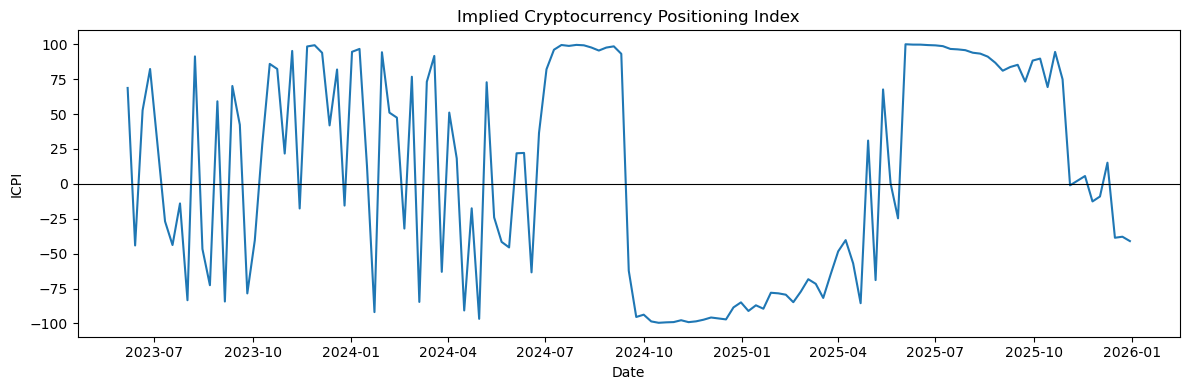

In [16]:
plot_df = cfpi_dataset.dropna(subset=["CFPI"]).copy()

if plot_df.empty:
    print("No non-missing CFPI observations to plot. Check basis coverage or CONFIG['ROLLING_WINDOW'].")
else:
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(plot_df["date"], plot_df["CFPI"], linewidth=1.5)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title("Implied Cryptocurrency Positioning Index")
    ax.set_xlabel("Date")
    ax.set_ylabel("CFPI")
    fig.tight_layout()
    plt.show()


## Regression helpers

OLS with Newey–West (HAC) standard errors, with the number of lags equal to the forecast horizon.

In [17]:
def run_hac_ols(df, y_col, x_cols, horizon):
    reg = df[[y_col] + x_cols].replace([np.inf, -np.inf], np.nan).dropna().copy()

    configured_lags = CONFIG["HAC_MAXLAGS_BY_HORIZON"].get(horizon)
    maxlags = horizon if configured_lags is None else configured_lags

    params = ["const"] + list(x_cols)
    min_required = len(params) + 1

    if len(reg) < min_required:
        print(
            f"Insufficient observations for {y_col} on {x_cols}: "
            f"n={len(reg)}, minimum needed={min_required}. Returning explicit NA rows."
        )
        rows = []
        for param in params:
            rows.append({
                "horizon": horizon,
                "dependent_variable": y_col,
                "parameter": param,
                "coef": np.nan,
                "std_err_hac": np.nan,
                "t_stat_hac": np.nan,
                "p_value_hac": np.nan,
                "ci_low_95": np.nan,
                "ci_high_95": np.nan,
                "n_obs": int(len(reg)),
                "r_squared": np.nan,
                "adj_r_squared": np.nan,
                "hac_maxlags": maxlags,
                "sample_start": reg.index.min() if len(reg) else pd.NaT,
                "sample_end": reg.index.max() if len(reg) else pd.NaT,
                "status": "insufficient_observations",
            })
        return pd.DataFrame(rows), None

    if len(reg) < 30:
        warnings.warn(f"Regression {y_col} with {x_cols} has only {len(reg)} observations.")

    y = reg[y_col]
    X = sm.add_constant(reg[x_cols], has_constant="add")

    fit = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": maxlags})
    conf = fit.conf_int()

    rows = []
    for param in fit.params.index:
        rows.append({
            "horizon": horizon,
            "dependent_variable": y_col,
            "parameter": param,
            "coef": float(fit.params[param]),
            "std_err_hac": float(fit.bse[param]),
            "t_stat_hac": float(fit.tvalues[param]),
            "p_value_hac": float(fit.pvalues[param]),
            "ci_low_95": float(conf.loc[param, 0]),
            "ci_high_95": float(conf.loc[param, 1]),
            "n_obs": int(fit.nobs),
            "r_squared": float(fit.rsquared),
            "adj_r_squared": float(fit.rsquared_adj),
            "hac_maxlags": maxlags,
            "sample_start": reg.index.min(),
            "sample_end": reg.index.max(),
            "status": "estimated",
        })

    return pd.DataFrame(rows), fit


def attach_date_index(df):
    out = df.copy()
    out["date"] = pd.to_datetime(out["date"])
    return out.sort_values("date").set_index("date")


## Regressions with each component on its own

In [18]:
reg_df = attach_date_index(cfpi_dataset)

individual_variables = {
    "P_crypto": "P_crypto",
    "B_crypto": "B_crypto",
    "C_crypto": "C_crypto",
}

individual_results = []
individual_models = {}

for h in CONFIG["HORIZONS"]:
    y_col = f"R_fwd_{h}"

    for label, x_col in individual_variables.items():
        x_cols = ["R_t", "Google_t", x_col]
        table, model = run_hac_ols(reg_df, y_col=y_col, x_cols=x_cols, horizon=h)
        table["specification"] = f"individual_{label}"
        table["main_predictor"] = label
        individual_results.append(table)
        individual_models[(h, label)] = model

regression_results_individual = pd.concat(individual_results, ignore_index=True)

display(regression_results_individual)
regression_results_individual.to_csv(OUTPUT_DIR / "regression_results_individual.csv", index=False)


,horizon,dependent_variable,parameter,coef,std_err_hac,t_stat_hac,p_value_hac,ci_low_95,ci_high_95,n_obs,r_squared,adj_r_squared,hac_maxlags,sample_start,sample_end,status,specification,main_predictor
0,1,R_fwd_1,const,0.011201,0.016316,0.686505,0.492395,-0.020777,0.043179,240,0.010881,-0.001693,1,2021-05-11,2025-12-23,estimated,individual_P_crypto,P_crypto
1,1,R_fwd_1,R_t,-0.097063,0.061355,-1.582002,0.113649,-0.217316,0.023190,240,0.010881,-0.001693,1,2021-05-11,2025-12-23,estimated,individual_P_crypto,P_crypto
2,1,R_fwd_1,Google_t,-0.001252,0.009965,-0.125633,0.900023,-0.020782,0.018279,240,0.010881,-0.001693,1,2021-05-11,2025-12-23,estimated,individual_P_crypto,P_crypto
3,1,R_fwd_1,P_crypto,-0.017667,0.043227,-0.408716,0.682748,-0.102390,0.067055,240,0.010881,-0.001693,1,2021-05-11,2025-12-23,estimated,individual_P_crypto,P_crypto
4,1,R_fwd_1,const,0.004491,0.006061,0.740969,0.458712,-0.007388,0.016370,240,0.017155,0.004661,1,2021-05-11,2025-12-23,estimated,individual_B_crypto,B_crypto
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,8,R_fwd_8,B_crypto,1.748320,1.242552,1.407039,0.159416,-0.687038,4.183677,234,0.008093,-0.004845,8,2021-05-11,2025-11-04,estimated,individual_B_crypto,B_crypto
68,8,R_fwd_8,const,0.050798,0.038680,1.313281,0.189088,-0.025014,0.126610,234,0.004798,-0.008182,8,2021-05-11,2025-11-04,estimated,individual_C_crypto,C_crypto
69,8,R_fwd_8,R_t,-0.119212,0.169321,-0.704056,0.481398,-0.451075,0.212652,234,0.004798,-0.008182,8,2021-05-11,2025-11-04,estimated,individual_C_crypto,C_crypto
70,8,R_fwd_8,Google_t,-0.011690,0.024678,-0.473726,0.635695,-0.060058,0.036677,234,0.004798,-0.008182,8,2021-05-11,2025-11-04,estimated,individual_C_crypto,C_crypto


## The main regressions with the CFPI

In [19]:
cfpi_results = []
cfpi_models = {}

for h in CONFIG["HORIZONS"]:
    y_col = f"R_fwd_{h}"
    x_cols = ["R_t", "Google_t", "CFPI"]

    table, model = run_hac_ols(reg_df, y_col=y_col, x_cols=x_cols, horizon=h)
    table["specification"] = "main_cfpi"
    table["main_predictor"] = "CFPI"
    cfpi_results.append(table)
    cfpi_models[h] = model

regression_results_cfpi = pd.concat(cfpi_results, ignore_index=True)

display(regression_results_cfpi)
regression_results_cfpi.to_csv(OUTPUT_DIR / "regression_results_cfpi.csv", index=False)


,horizon,dependent_variable,parameter,coef,std_err_hac,t_stat_hac,p_value_hac,ci_low_95,ci_high_95,n_obs,r_squared,adj_r_squared,hac_maxlags,sample_start,sample_end,status,specification,main_predictor
0,1,R_fwd_1,const,0.011056,0.006730,1.642718,0.100441,-0.002135,0.024248,132,0.050479,0.028225,1,2023-06-06,2025-12-23,estimated,main_icpi,ICPI
1,1,R_fwd_1,R_t,-0.165334,0.078738,-2.099812,0.035745,-0.319657,-0.011011,132,0.050479,0.028225,1,2023-06-06,2025-12-23,estimated,main_icpi,ICPI
2,1,R_fwd_1,Google_t,0.012712,0.010576,1.201988,0.229368,-0.008016,0.033440,132,0.050479,0.028225,1,2023-06-06,2025-12-23,estimated,main_icpi,ICPI
3,1,R_fwd_1,ICPI,-0.000015,0.000083,-0.175785,0.860463,-0.000176,0.000147,132,0.050479,0.028225,1,2023-06-06,2025-12-23,estimated,main_icpi,ICPI
4,2,R_fwd_2,const,0.019313,0.011454,1.686105,0.091776,-0.003137,0.041763,131,0.009490,-0.013908,2,2023-06-06,2025-12-16,estimated,main_icpi,ICPI
5,2,R_fwd_2,R_t,-0.035989,0.093781,-0.383754,0.701161,-0.219797,0.147819,131,0.009490,-0.013908,2,2023-06-06,2025-12-16,estimated,main_icpi,ICPI
6,2,R_fwd_2,Google_t,0.008813,0.014863,0.592961,0.553207,-0.020318,0.037945,131,0.009490,-0.013908,2,2023-06-06,2025-12-16,estimated,main_icpi,ICPI
7,2,R_fwd_2,ICPI,0.000055,0.000134,0.407598,0.683569,-0.000209,0.000318,131,0.009490,-0.013908,2,2023-06-06,2025-12-16,estimated,main_icpi,ICPI
8,3,R_fwd_3,const,0.029301,0.017971,1.630421,0.103013,-0.005922,0.064524,130,0.022089,-0.001195,3,2023-06-06,2025-12-09,estimated,main_icpi,ICPI
9,3,R_fwd_3,R_t,-0.068105,0.139237,-0.489131,0.624749,-0.341004,0.204794,130,0.022089,-0.001195,3,2023-06-06,2025-12-09,estimated,main_icpi,ICPI


## Robustness: the PCA score before the tanh

In [20]:
score_results = []
score_models = {}

for h in CONFIG["HORIZONS"]:
    y_col = f"R_fwd_{h}"
    x_cols = ["R_t", "Google_t", "CFPI_score_unbounded"]

    table, model = run_hac_ols(reg_df, y_col=y_col, x_cols=x_cols, horizon=h)
    table["specification"] = "robustness_unbounded_pca_score"
    table["main_predictor"] = "CFPI_score_unbounded"
    score_results.append(table)
    score_models[h] = model

regression_results_unbounded_score = pd.concat(score_results, ignore_index=True)

display(regression_results_unbounded_score)
regression_results_unbounded_score.to_csv(OUTPUT_DIR / "regression_results_unbounded_score.csv", index=False)


,horizon,dependent_variable,parameter,coef,std_err_hac,t_stat_hac,p_value_hac,ci_low_95,ci_high_95,n_obs,r_squared,adj_r_squared,hac_maxlags,sample_start,sample_end,status,specification,main_predictor
0,1,R_fwd_1,const,0.011068,0.006714,1.648391,0.099273,-0.002092,0.024228,132,0.050381,0.028124,1,2023-06-06,2025-12-23,estimated,robustness_unbounded_pca_score,ICPI_score_unbounded
1,1,R_fwd_1,R_t,-0.166281,0.079335,-2.095932,0.036088,-0.321776,-0.010787,132,0.050381,0.028124,1,2023-06-06,2025-12-23,estimated,robustness_unbounded_pca_score,ICPI_score_unbounded
2,1,R_fwd_1,Google_t,0.012670,0.010608,1.194366,0.232335,-0.008122,0.033462,132,0.050381,0.028124,1,2023-06-06,2025-12-23,estimated,robustness_unbounded_pca_score,ICPI_score_unbounded
3,1,R_fwd_1,ICPI_score_unbounded,-0.000506,0.004038,-0.125328,0.900264,-0.008421,0.007408,132,0.050381,0.028124,1,2023-06-06,2025-12-23,estimated,robustness_unbounded_pca_score,ICPI_score_unbounded
4,2,R_fwd_2,const,0.019874,0.011508,1.726975,0.084172,-0.002681,0.042428,131,0.007899,-0.015536,2,2023-06-06,2025-12-16,estimated,robustness_unbounded_pca_score,ICPI_score_unbounded
5,2,R_fwd_2,R_t,-0.031617,0.096382,-0.328043,0.742880,-0.220522,0.157287,131,0.007899,-0.015536,2,2023-06-06,2025-12-16,estimated,robustness_unbounded_pca_score,ICPI_score_unbounded
6,2,R_fwd_2,Google_t,0.008726,0.014478,0.602725,0.546691,-0.019651,0.037104,131,0.007899,-0.015536,2,2023-06-06,2025-12-16,estimated,robustness_unbounded_pca_score,ICPI_score_unbounded
7,2,R_fwd_2,ICPI_score_unbounded,-0.000437,0.006897,-0.063312,0.949518,-0.013955,0.013082,131,0.007899,-0.015536,2,2023-06-06,2025-12-16,estimated,robustness_unbounded_pca_score,ICPI_score_unbounded
8,3,R_fwd_3,const,0.030285,0.018113,1.672049,0.094515,-0.005215,0.065786,130,0.024585,0.001360,3,2023-06-06,2025-12-09,estimated,robustness_unbounded_pca_score,ICPI_score_unbounded
9,3,R_fwd_3,R_t,-0.068088,0.140712,-0.483885,0.628467,-0.343878,0.207701,130,0.024585,0.001360,3,2023-06-06,2025-12-09,estimated,robustness_unbounded_pca_score,ICPI_score_unbounded


## Compact tables

In [21]:
def make_compact_table(results, predictor_name):
    out = results[results["parameter"] == predictor_name].copy()
    cols = [
        "specification", "horizon", "parameter",
        "coef", "std_err_hac", "t_stat_hac", "p_value_hac",
        "n_obs", "r_squared", "hac_maxlags",
    ]
    if "status" in out.columns:
        cols.append("status")
    return out[cols].sort_values(["specification", "horizon"])


compact_individual = pd.concat(
    [
        make_compact_table(regression_results_individual, "P_crypto"),
        make_compact_table(regression_results_individual, "B_crypto"),
        make_compact_table(regression_results_individual, "C_crypto"),
    ],
    ignore_index=True,
)

compact_cfpi = make_compact_table(regression_results_cfpi, "CFPI")
compact_score = make_compact_table(regression_results_unbounded_score, "CFPI_score_unbounded")

display(compact_individual)
display(compact_cfpi)
display(compact_score)

compact_individual.to_csv(OUTPUT_DIR / "regression_results_individual_compact.csv", index=False)
compact_cfpi.to_csv(OUTPUT_DIR / "regression_results_cfpi_compact.csv", index=False)
compact_score.to_csv(OUTPUT_DIR / "regression_results_unbounded_score_compact.csv", index=False)


,specification,horizon,parameter,coef,std_err_hac,t_stat_hac,p_value_hac,n_obs,r_squared,hac_maxlags,status
0,individual_P_crypto,1,P_crypto,-0.017667,0.043227,-0.408716,0.682748,240,0.010881,1,estimated
1,individual_P_crypto,2,P_crypto,-0.035481,0.073930,-0.479922,0.631283,239,0.005160,2,estimated
2,individual_P_crypto,3,P_crypto,-0.065324,0.108229,-0.603578,0.546124,238,0.005165,3,estimated
3,individual_P_crypto,4,P_crypto,-0.094885,0.134597,-0.704955,0.480838,237,0.010219,4,estimated
4,individual_P_crypto,6,P_crypto,-0.147524,0.181972,-0.810699,0.417539,235,0.012203,6,estimated
5,individual_P_crypto,8,P_crypto,-0.210592,0.204518,-1.029703,0.303150,234,0.019660,8,estimated
6,individual_B_crypto,1,B_crypto,0.681613,0.447828,1.522043,0.127998,240,0.017155,1,estimated
7,individual_B_crypto,2,B_crypto,1.177901,0.799019,1.474184,0.140432,239,0.014977,2,estimated
8,individual_B_crypto,3,B_crypto,0.492099,0.898599,0.547629,0.583947,238,0.001849,3,estimated
9,individual_B_crypto,4,B_crypto,1.179241,1.220521,0.966178,0.333955,237,0.008605,4,estimated


,specification,horizon,parameter,coef,std_err_hac,t_stat_hac,p_value_hac,n_obs,r_squared,hac_maxlags,status
3,main_icpi,1,ICPI,-0.000015,0.000083,-0.175785,0.860463,132,0.050479,1,estimated
7,main_icpi,2,ICPI,0.000055,0.000134,0.407598,0.683569,131,0.009490,2,estimated
11,main_icpi,3,ICPI,-0.000016,0.000202,-0.078981,0.937048,130,0.022089,3,estimated
15,main_icpi,4,ICPI,-0.000047,0.000276,-0.170322,0.864757,129,0.023692,4,estimated
19,main_icpi,6,ICPI,-0.000023,0.000431,-0.052374,0.958230,127,0.012667,6,estimated
23,main_icpi,8,ICPI,-0.000067,0.000560,-0.119192,0.905123,126,0.011274,8,estimated


,specification,horizon,parameter,coef,std_err_hac,t_stat_hac,p_value_hac,n_obs,r_squared,hac_maxlags,status
3,robustness_unbounded_pca_score,1,ICPI_score_unbounded,-0.000506,0.004038,-0.125328,0.900264,132,0.050381,1,estimated
7,robustness_unbounded_pca_score,2,ICPI_score_unbounded,-0.000437,0.006897,-0.063312,0.949518,131,0.007899,2,estimated
11,robustness_unbounded_pca_score,3,ICPI_score_unbounded,-0.004319,0.010407,-0.415016,0.678130,130,0.024585,3,estimated
15,robustness_unbounded_pca_score,4,ICPI_score_unbounded,-0.005664,0.014206,-0.398719,0.690101,129,0.026335,4,estimated
19,robustness_unbounded_pca_score,6,ICPI_score_unbounded,-0.001721,0.022520,-0.076415,0.939089,127,0.012767,6,estimated
23,robustness_unbounded_pca_score,8,ICPI_score_unbounded,-0.001704,0.028070,-0.060709,0.951591,126,0.010925,8,estimated


## Saving the final dataset

cfpi_variants.py picks up this file.

In [22]:
final_cols = [
    "date",
    "R_t",
    "Google_t",
    "Google_raw",
    "Google_search",
    "R_source",
    "P_crypto",
    "B_crypto",
    "C_crypto",
    "basis_measure",
    "basis_price_source",
    "total_open_interest_notional_usd",
    "delta_log_total_oi",
    "psi_P_crypto",
    "psi_B_crypto",
    "psi_C_crypto",
    "z_P_crypto",
    "z_B_crypto",
    "z_C_crypto",
    "CFPI_score_unbounded",
    "CFPI",
] + [f"R_fwd_{h}" for h in CONFIG["HORIZONS"]]

available_final_cols = [c for c in final_cols if c in cfpi_dataset.columns]
missing_final_cols = [c for c in final_cols if c not in cfpi_dataset.columns]
if missing_final_cols:
    print("Final dataset columns not available and omitted:", missing_final_cols)
final_regression_dataset = cfpi_dataset[available_final_cols].copy()
final_regression_dataset.to_csv(OUTPUT_DIR / "final_merged_regression_dataset.csv", index=False)

print("Saved outputs to:", OUTPUT_DIR)
print("Key files:")
for name in [
    "clean_cftc_positions_contract_level.csv",
    "crypto_positioning_components_asset_level.csv",
    "crypto_positioning_components.csv",
    "cfpi_dataset.csv",
    "final_merged_regression_dataset.csv",
    "regression_results_individual.csv",
    "regression_results_cfpi.csv",
    "pca_loadings.csv",
]:
    print("-", OUTPUT_DIR / name)


Saved outputs to: /Users/berkyilmaz/Desktop/Masters Thesis/FI-thesis-template/outputs
Key files:
- /Users/berkyilmaz/Desktop/Masters Thesis/FI-thesis-template/outputs/clean_cftc_positions_contract_level.csv
- /Users/berkyilmaz/Desktop/Masters Thesis/FI-thesis-template/outputs/crypto_positioning_components_asset_level.csv
- /Users/berkyilmaz/Desktop/Masters Thesis/FI-thesis-template/outputs/crypto_positioning_components.csv
- /Users/berkyilmaz/Desktop/Masters Thesis/FI-thesis-template/outputs/icpi_dataset.csv
- /Users/berkyilmaz/Desktop/Masters Thesis/FI-thesis-template/outputs/final_merged_regression_dataset.csv
- /Users/berkyilmaz/Desktop/Masters Thesis/FI-thesis-template/outputs/regression_results_individual.csv
- /Users/berkyilmaz/Desktop/Masters Thesis/FI-thesis-template/outputs/regression_results_icpi.csv
- /Users/berkyilmaz/Desktop/Masters Thesis/FI-thesis-template/outputs/pca_loadings.csv


## LaTeX tables for the thesis

The `#|` lines are Quarto options I used when rendering the thesis.

In [23]:
#| label: extension-latex-table-helpers
#| echo: false

import re

EXTENSION_HORIZONS = CONFIG["HORIZONS"]
EXTENSION_HORIZON_LABELS = {
    1: r"R$_{t,t+1}$ (1)",
    2: r"R$_{t,t+2}$ (2)",
    3: r"R$_{t,t+3}$ (3)",
    4: r"R$_{t,t+4}$ (4)",
    6: r"R$_{t,t+6}$ (5)",
    8: r"R$_{t,t+8}$ (6)",
}

EXTENSION_VAR_LABELS = {
    "const": "Constant",
    "R_t": r"R$_t$",
    "Google_t": r"Google$_t$",
    "P_crypto": r"P$^{Crypto}_t$",
    "B_crypto": r"B$^{Crypto}_t$",
    "C_crypto": r"C$^{Crypto}_t$",
    "CFPI": r"CFPI$_t$",
    "CFPI_score_unbounded": "PCA score",
}


def latex_escape_text(x):
    """Escapes text for LaTeX but leaves the math strings alone (mostly)"""
    if pd.isna(x):
        return ""
    x = str(x)
    if "$" in x or "\\" in x:
        return x
    replacements = {
        "&": r"\&",
        "%": r"\%",
        "#": r"\#",
        "_": r"\_",
    }
    for old, new in replacements.items():
        x = x.replace(old, new)
    return x


def significance_stars_from_p(p):
    if pd.isna(p):
        return ""
    if p < 0.01:
        return "***"
    if p < 0.05:
        return "**"
    if p < 0.10:
        return "*"
    return ""


def format_num_latex(x, digits=3):
    if pd.isna(x) or not np.isfinite(x):
        return ""
    return f"{x:.{digits}f}"


def format_coef_tstat(coef, tstat, pval, digits=3):
    if pd.isna(coef):
        return ""
    stars = significance_stars_from_p(pval)
    return rf"\shortstack[c]{{{coef:.{digits}f}{stars} \\ ({tstat:.2f})}}"


def format_plain_percent(x, digits=2):
    if pd.isna(x) or not np.isfinite(x):
        return ""
    return f"{100 * x:.{digits}f}"


def latex_resizebox_table(df, caption, label, column_format=None, note=None, font_size=r"\footnotesize"):
    """
    Turns a DataFrame into a LaTeX table that fits the page (Styler.to_latex + resizebox).
    Same approach as my other thesis tables.
    """
    out = df.copy()
    out = out.applymap(lambda x: "" if pd.isna(x) else str(x))

    if column_format is None:
        column_format = "l" + "c" * (out.shape[1] - 1)

    latex_table = (
        out.style
        .hide(axis="index")
        .to_latex(
            column_format=column_format,
            position="!htbp",
            position_float="centering",
            hrules=True,
            caption=caption,
            label=label,
            convert_css=False,
        )
    )

    latex_table = latex_table.replace(
        r"\begin{tabular}",
        font_size + "\n" + r"\resizebox{\linewidth}{!}{%" + "\n" + r"\begin{tabular}",
        1,
    ).replace(
        r"\end{tabular}",
        r"\end{tabular}" + "\n" + r"}%",
        1,
    )

    if note:
        note_text = r"\begin{minipage}{0.98\linewidth}" + "\n" + r"\vspace{0.25em}\scriptsize " + note + "\n" + r"\end{minipage}"
        latex_table = latex_table.replace(r"\end{table}", note_text + "\n" + r"\end{table}")

    return latex_table


def regression_lookup(results):
    return results.set_index(["horizon", "parameter"])


def get_reg_value(results, horizon, parameter, field):
    idx = (horizon, parameter)
    lookup = regression_lookup(results)
    if idx not in lookup.index:
        return np.nan
    value = lookup.loc[idx, field]
    if isinstance(value, pd.Series):
        value = value.iloc[0]
    return value


def make_regression_panel(results, row_vars, include_fit_rows=True):
    rows = []
    for var in row_vars:
        row = {"Variable": EXTENSION_VAR_LABELS.get(var, latex_escape_text(var))}
        for h in EXTENSION_HORIZONS:
            coef = get_reg_value(results, h, var, "coef")
            tval = get_reg_value(results, h, var, "t_stat_hac")
            pval = get_reg_value(results, h, var, "p_value_hac")
            row[EXTENSION_HORIZON_LABELS[h]] = format_coef_tstat(coef, tval, pval)
        rows.append(row)

    if include_fit_rows:
        r2_row = {"Variable": r"R$^2$"}
        n_row = {"Variable": "N"}
        for h in EXTENSION_HORIZONS:
            # R2 and N are the same for every row within a horizon, so I just take the first one
            sub = results.loc[results["horizon"] == h]
            if sub.empty:
                r2_row[EXTENSION_HORIZON_LABELS[h]] = ""
                n_row[EXTENSION_HORIZON_LABELS[h]] = ""
            else:
                r2_row[EXTENSION_HORIZON_LABELS[h]] = format_num_latex(sub["r_squared"].iloc[0], digits=3)
                n_row[EXTENSION_HORIZON_LABELS[h]] = str(int(sub["n_obs"].iloc[0])) if pd.notna(sub["n_obs"].iloc[0]) else ""
        rows.extend([r2_row, n_row])

    return pd.DataFrame(rows)


In [24]:
#| label: tbl-extension-summary-statistics
#| tbl-cap: "Summary statistics for extension variables."
#| echo: false
#| output: asis

summary_vars = [
    "R_t", "Google_t", "P_crypto", "B_crypto", "C_crypto", "CFPI"
]
summary_df = cfpi_dataset[summary_vars].describe().T.reset_index().rename(columns={"index": "Variable"})

summary_label_map = {
    "R_t": r"R$_t$",
    "Google_t": r"Google$_t$",
    "P_crypto": r"P$^{Crypto}_t$",
    "B_crypto": r"B$^{Crypto}_t$",
    "C_crypto": r"C$^{Crypto}_t$",
    "CFPI": r"CFPI$_t$",
}

summary_display = pd.DataFrame({
    "Variable": summary_df["Variable"].map(summary_label_map),
    "N": summary_df["count"].map(lambda x: str(int(x)) if pd.notna(x) else ""),
    "Mean": summary_df["mean"].map(lambda x: format_num_latex(x, 3)),
    "SD": summary_df["std"].map(lambda x: format_num_latex(x, 3)),
    "Min": summary_df["min"].map(lambda x: format_num_latex(x, 3)),
    "Median": summary_df["50%"].map(lambda x: format_num_latex(x, 3)),
    "Max": summary_df["max"].map(lambda x: format_num_latex(x, 3)),
})

sample_start = pd.to_datetime(cfpi_dataset["date"]).min().date()
sample_end = pd.to_datetime(cfpi_dataset["date"]).max().date()
return_source = cfpi_dataset["R_source"].mode().iloc[0] if "R_source" in cfpi_dataset.columns else "selected return proxy"
basis_measure = cfpi_dataset["basis_measure"].mode().iloc[0] if "basis_measure" in cfpi_dataset.columns else CONFIG["BASIS"].get("basis_measure", "basis proxy")

note = (
    f"Sample period is {sample_start} to {sample_end}. "
    f"The dependent return source is {latex_escape_text(return_source)}. "
    f"The pricing-pressure measure is {latex_escape_text(basis_measure)}."
)

print(latex_resizebox_table(
    summary_display,
    caption="Summary statistics for extension variables.",
    label="tbl-extension-summary-statistics",
    column_format="lcccccc",
    note=note,
))


\begin{table}[!htbp]
\centering
\caption{Summary statistics for extension variables.}
\label{tbl-extension-summary-statistics}
\footnotesize
\resizebox{\linewidth}{!}{%
\begin{tabular}{lcccccc}
\toprule
Variable & N & Mean & SD & Min & Median & Max \\
\midrule
R$_t$ & 241 & 0.005 & 0.091 & -0.310 & 0.005 & 0.345 \\
Google$_t$ & 241 & -0.005 & 1.001 & -3.160 & -0.023 & 5.848 \\
P$^{Crypto}_t$ & 241 & 0.315 & 0.159 & -0.065 & 0.287 & 0.640 \\
B$^{Crypto}_t$ & 241 & 0.002 & 0.011 & -0.038 & 0.002 & 0.044 \\
C$^{Crypto}_t$ & 241 & 0.011 & 0.125 & -0.276 & -0.001 & 0.472 \\
ICPI$_t$ & 133 & 8.139 & 75.986 & -99.553 & 15.118 & 99.969 \\
\bottomrule
\end{tabular}
}%
\begin{minipage}{0.98\linewidth}
\vspace{0.25em}\scriptsize Sample period is 2021-05-11 to 2025-12-30. The dependent return source is yahoo\_btc\_eth\_proxy. The pricing-pressure measure is log\_continuous\_futures\_premium.
\end{minipage}
\end{table}



/var/folders/02/hw2xskd17854kzhgq2xw_1hm0000gn/T/ipykernel_54971/1202336892.py:83: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  out = out.applymap(lambda x: "" if pd.isna(x) else str(x))


In [25]:
#| label: tbl-extension-correlation-matrix
#| tbl-cap: "Correlation matrix of CFPI components and controls."
#| echo: false
#| output: asis

corr_vars = ["R_t", "Google_t", "P_crypto", "B_crypto", "C_crypto", "CFPI"]
corr = cfpi_dataset[corr_vars].corr()

corr_names = {
    "R_t": r"R$_t$",
    "Google_t": r"Google$_t$",
    "P_crypto": r"P$^{Crypto}$",
    "B_crypto": r"B$^{Crypto}$",
    "C_crypto": r"C$^{Crypto}$",
    "CFPI": "CFPI",
}

corr_display = corr.copy()
corr_display.index = [corr_names[c] for c in corr_display.index]
corr_display.columns = [corr_names[c] for c in corr_display.columns]

for r in range(corr_display.shape[0]):
    for c in range(corr_display.shape[1]):
        if c < r:
            corr_display.iloc[r, c] = np.nan

corr_display = corr_display.applymap(lambda x: "" if pd.isna(x) else f"{x:.2f}")
corr_display.insert(0, "Variable", corr_display.index)
corr_display = corr_display.reset_index(drop=True)

print(latex_resizebox_table(
    corr_display,
    caption="Correlation matrix of CFPI components and controls.",
    label="tbl-extension-correlation-matrix",
    column_format="l" + "c" * len(corr_vars),
))


\begin{table}[!htbp]
\centering
\caption{Correlation matrix of ICPI components and controls.}
\label{tbl-extension-correlation-matrix}
\footnotesize
\resizebox{\linewidth}{!}{%
\begin{tabular}{lcccccc}
\toprule
Variable & R$_t$ & Google$_t$ & P$^{Crypto}$ & B$^{Crypto}$ & C$^{Crypto}$ & ICPI \\
\midrule
R$_t$ & 1.00 & -0.01 & 0.02 & 0.03 & 0.61 & 0.08 \\
Google$_t$ &  & 1.00 & 0.01 & 0.08 & 0.05 & -0.00 \\
P$^{Crypto}$ &  &  & 1.00 & 0.17 & -0.11 & 0.24 \\
B$^{Crypto}$ &  &  &  & 1.00 & 0.10 & 0.37 \\
C$^{Crypto}$ &  &  &  &  & 1.00 & 0.17 \\
ICPI &  &  &  &  &  & 1.00 \\
\bottomrule
\end{tabular}
}%
\end{table}



/var/folders/02/hw2xskd17854kzhgq2xw_1hm0000gn/T/ipykernel_54971/2154859431.py:27: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  corr_display = corr_display.applymap(lambda x: "" if pd.isna(x) else f"{x:.2f}")
/var/folders/02/hw2xskd17854kzhgq2xw_1hm0000gn/T/ipykernel_54971/1202336892.py:83: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  out = out.applymap(lambda x: "" if pd.isna(x) else str(x))


In [26]:
#| label: tbl-extension-individual-regressions
#| tbl-cap: "Individual predictive regressions for futures-positioning variables."
#| echo: false
#| output: asis

panel_rows = []
for predictor, panel_title in [
    ("P_crypto", r"\textit{Panel A: Crowding, } P$^{Crypto}_t$"),
    ("B_crypto", r"\textit{Panel B: Pricing pressure, } B$^{Crypto}_t$"),
    ("C_crypto", r"\textit{Panel C: Participation, } C$^{Crypto}_t$"),
]:
    spec = f"individual_{predictor}"
    res = regression_results_individual.loc[regression_results_individual["specification"] == spec].copy()
    panel_rows.append({"Variable": panel_title, **{EXTENSION_HORIZON_LABELS[h]: "" for h in EXTENSION_HORIZONS}})
    panel = make_regression_panel(res, [predictor], include_fit_rows=True)
    panel_rows.extend(panel.to_dict("records"))

individual_latex_df = pd.DataFrame(panel_rows)

note = (
    r"Each column reports a separate predictive regression of future returns on current return, "
    r"Google attention, and the listed futures-positioning variable. HAC/Newey--West "
    r"standard errors are used with maxlags equal to the forecasting horizon. "
    r"t-statistics are in parentheses. *, **, and *** denote significance at the 10\%, 5\%, and 1\% levels."
)

print(latex_resizebox_table(
    individual_latex_df,
    caption="Individual predictive regressions for futures-positioning variables.",
    label="tbl-extension-individual-regressions",
    column_format="l" + "c" * len(EXTENSION_HORIZONS),
    note=note,
))


\begin{table}[!htbp]
\centering
\caption{Individual predictive regressions for futures-positioning variables.}
\label{tbl-extension-individual-regressions}
\footnotesize
\resizebox{\linewidth}{!}{%
\begin{tabular}{lcccccc}
\toprule
Variable & R$_{t,t+1}$ (1) & R$_{t,t+2}$ (2) & R$_{t,t+3}$ (3) & R$_{t,t+4}$ (4) & R$_{t,t+6}$ (5) & R$_{t,t+8}$ (6) \\
\midrule
\textit{Panel A: Crowding, } P$^{Crypto}_t$ &  &  &  &  &  &  \\
P$^{Crypto}_t$ & \shortstack[c]{-0.018 \\ (-0.41)} & \shortstack[c]{-0.035 \\ (-0.48)} & \shortstack[c]{-0.065 \\ (-0.60)} & \shortstack[c]{-0.095 \\ (-0.70)} & \shortstack[c]{-0.148 \\ (-0.81)} & \shortstack[c]{-0.211 \\ (-1.03)} \\
R$^2$ & 0.011 & 0.005 & 0.005 & 0.010 & 0.012 & 0.020 \\
N & 240 & 239 & 238 & 237 & 235 & 234 \\
\textit{Panel B: Pricing pressure, } B$^{Crypto}_t$ &  &  &  &  &  &  \\
B$^{Crypto}_t$ & \shortstack[c]{0.682 \\ (1.52)} & \shortstack[c]{1.178 \\ (1.47)} & \shortstack[c]{0.492 \\ (0.55)} & \shortstack[c]{1.179 \\ (0.97)} & \shortstack[c]{1

/var/folders/02/hw2xskd17854kzhgq2xw_1hm0000gn/T/ipykernel_54971/1202336892.py:83: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  out = out.applymap(lambda x: "" if pd.isna(x) else str(x))


In [27]:
#| label: tbl-extension-cfpi-regressions
#| tbl-cap: "Predictive regressions with the CFPI."
#| echo: false
#| output: asis

cfpi_latex_df = make_regression_panel(
    regression_results_cfpi,
    ["R_t", "Google_t", "CFPI"],
    include_fit_rows=True,
)

note = (
    r"The dependent variable is the cumulative future BTC/ETH return proxy over horizon h. "
    r"CFPI is constructed from crowding, pricing pressure, and participation using rolling no-lookahead PCA. "
    r"HAC/Newey--West standard errors are used with maxlags equal to the forecasting horizon. "
    r"t-statistics are in parentheses. *, **, and *** denote significance at the 10\%, 5\%, and 1\% levels."
)

print(latex_resizebox_table(
    cfpi_latex_df,
    caption="Predictive regressions with the CFPI.",
    label="tbl-extension-cfpi-regressions",
    column_format="l" + "c" * len(EXTENSION_HORIZONS),
    note=note,
))


\begin{table}[!htbp]
\centering
\caption{Predictive regressions with the ICPI.}
\label{tbl-extension-icpi-regressions}
\footnotesize
\resizebox{\linewidth}{!}{%
\begin{tabular}{lcccccc}
\toprule
Variable & R$_{t,t+1}$ (1) & R$_{t,t+2}$ (2) & R$_{t,t+3}$ (3) & R$_{t,t+4}$ (4) & R$_{t,t+6}$ (5) & R$_{t,t+8}$ (6) \\
\midrule
R$_t$ & \shortstack[c]{-0.165** \\ (-2.10)} & \shortstack[c]{-0.036 \\ (-0.38)} & \shortstack[c]{-0.068 \\ (-0.49)} & \shortstack[c]{0.115 \\ (0.78)} & \shortstack[c]{0.051 \\ (0.28)} & \shortstack[c]{0.028 \\ (0.17)} \\
Google$_t$ & \shortstack[c]{0.013 \\ (1.20)} & \shortstack[c]{0.009 \\ (0.59)} & \shortstack[c]{0.019 \\ (1.17)} & \shortstack[c]{0.020 \\ (1.06)} & \shortstack[c]{0.022 \\ (0.91)} & \shortstack[c]{0.023 \\ (0.95)} \\
ICPI$_t$ & \shortstack[c]{-0.000 \\ (-0.18)} & \shortstack[c]{0.000 \\ (0.41)} & \shortstack[c]{-0.000 \\ (-0.08)} & \shortstack[c]{-0.000 \\ (-0.17)} & \shortstack[c]{-0.000 \\ (-0.05)} & \shortstack[c]{-0.000 \\ (-0.12)} \\
R$^2$ & 0.0

/var/folders/02/hw2xskd17854kzhgq2xw_1hm0000gn/T/ipykernel_54971/1202336892.py:83: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  out = out.applymap(lambda x: "" if pd.isna(x) else str(x))


In [28]:
#| label: tbl-extension-pca-loadings
#| tbl-cap: "Average CFPI rolling PCA loadings."
#| echo: false
#| output: asis

loadings_valid = pca_loadings.dropna(subset=["w_P", "w_B", "w_C"]).copy()

if loadings_valid.empty:
    pca_display = pd.DataFrame({
        "Loading": [r"w$_P$", r"w$_B$", r"w$_C$"],
        "Mean": ["", "", ""],
        "SD": ["", "", ""],
        "Min": ["", "", ""],
        "Max": ["", "", ""],
    })
else:
    rows = []
    for col, label in [("w_P", r"w$_P$"), ("w_B", r"w$_B$"), ("w_C", r"w$_C$")]:
        s = loadings_valid[col].dropna()
        rows.append({
            "Loading": label,
            "Mean": format_num_latex(s.mean(), 3),
            "SD": format_num_latex(s.std(ddof=1), 3),
            "Min": format_num_latex(s.min(), 3),
            "Max": format_num_latex(s.max(), 3),
        })
    pca_display = pd.DataFrame(rows)

note = (
    r"Loadings are from the first eigenvector of the rolling covariance matrix of standardized CFPI components. "
    r"The sign is normalized so that larger CFPI values correspond to more bullish institutional/professional positioning."
)

print(latex_resizebox_table(
    pca_display,
    caption="Average CFPI rolling PCA loadings.",
    label="tbl-extension-pca-loadings",
    column_format="lcccc",
    note=note,
))


\begin{table}[!htbp]
\centering
\caption{Average ICPI rolling PCA loadings.}
\label{tbl-extension-pca-loadings}
\footnotesize
\resizebox{\linewidth}{!}{%
\begin{tabular}{lcccc}
\toprule
Loading & Mean & SD & Min & Max \\
\midrule
w$_P$ & 0.644 & 0.405 & -0.790 & 0.998 \\
w$_B$ & 0.406 & 0.310 & -0.008 & 0.918 \\
w$_C$ & 0.203 & 0.350 & -0.315 & 0.925 \\
\bottomrule
\end{tabular}
}%
\begin{minipage}{0.98\linewidth}
\vspace{0.25em}\scriptsize Loadings are from the first eigenvector of the rolling covariance matrix of standardized ICPI components. The sign is normalized so that larger ICPI values correspond to more bullish institutional/professional positioning.
\end{minipage}
\end{table}



/var/folders/02/hw2xskd17854kzhgq2xw_1hm0000gn/T/ipykernel_54971/1202336892.py:83: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  out = out.applymap(lambda x: "" if pd.isna(x) else str(x))


## Notes on my choices

Things to keep in mind when reading the results:

1. CFTC dates are the position dates (`report_date_as_mm_dd_yyyy`), not the publication dates.
2. I only use the CME Bitcoin, Micro Bitcoin, Ether and Micro Ether contracts. Nano contracts and other exchanges are left out.
3. The contract multipliers are 5 BTC and 0.1 BTC for Bitcoin, and 50 ETH and 0.1 ETH for Ether.
4. The basis is a proxy: `B = ln(F/S)` on the continuous CME contract (`BTC=F`, `ETH=F`). The continuous series is rolled, so I don't scale it by time to expiry, which means it is not the exact nearest-maturity basis.
5. CMKT in `Dataset.csv` stops in 2021, so the return in the extension is an equal-weighted BTC/ETH return from Yahoo, not the original coin market index.
6. Returns are simple returns, same as in the replication.
7. Google attention is built the same way as in the replication: `bitcoin_search` minus its prior 4-week mean, standardized after the weekly aggregation.
8. I check the missing values, sample dates, correlations and PCA loadings before reading anything into the CFPI coefficient.

In [29]:
#| label: extension-table11-interaction-regressions
#| echo: false
#| warning: false
#| message: false

# Liu and Tsyvinski Table 11, bottom two specifications, with the CFPI added
#
# Panel A: R_{t,t+h} = a + b R_t + c 1{Google_t > 0} + d R_t x 1{Google_t > 0} + e CFPI_t + error
# Panel B: R_{t,t+h} = a + b Google_t + c 1{R_t > 0} + d Google_t x 1{R_t > 0} + e CFPI_t + error

ADDED_POSITIONING_VARIABLE = "CFPI"

try:
    table11_df = attach_date_index(cfpi_dataset).copy()
except NameError:
    table11_df = cfpi_dataset.copy()
    table11_df["date"] = pd.to_datetime(table11_df["date"], errors="coerce")
    table11_df = table11_df.set_index("date", drop=False).sort_index()

required_cols = [
    "R_t",
    "Google_t",
    ADDED_POSITIONING_VARIABLE,
] + [f"R_fwd_{h}" for h in CONFIG["HORIZONS"]]

missing_cols = [c for c in required_cols if c not in table11_df.columns]

if missing_cols:
    raise ValueError(f"Missing columns required for Table 11 interaction regressions: {missing_cols}")

table11_df["High_Google_t"] = (table11_df["Google_t"] > 0).astype(float)
table11_df["High_R_t"] = (table11_df["R_t"] > 0).astype(float)

table11_df["R_t_x_High_Google_t"] = table11_df["R_t"] * table11_df["High_Google_t"]
table11_df["Google_t_x_High_R_t"] = table11_df["Google_t"] * table11_df["High_R_t"]

table11_results = []
table11_models = {}

for h in CONFIG["HORIZONS"]:
    y_col = f"R_fwd_{h}"

    # Panel A: Momentum conditional on high Google attention
    x_cols_panel_a = [
        "R_t",
        "High_Google_t",
        "R_t_x_High_Google_t",
        ADDED_POSITIONING_VARIABLE,
    ]

    table_a, model_a = run_hac_ols(
        table11_df,
        y_col=y_col,
        x_cols=x_cols_panel_a,
        horizon=h,
    )

    table_a["specification"] = "table11_bottom_panel_a_momentum_high_google_with_cfpi"
    table_a["panel"] = "Panel A"
    table_a["main_predictor"] = "R_t_x_High_Google_t"

    table11_results.append(table_a)
    table11_models[(h, "Panel A")] = model_a

    # Panel B: Google attention conditional on positive current returns
    x_cols_panel_b = [
        "Google_t",
        "High_R_t",
        "Google_t_x_High_R_t",
        ADDED_POSITIONING_VARIABLE,
    ]

    table_b, model_b = run_hac_ols(
        table11_df,
        y_col=y_col,
        x_cols=x_cols_panel_b,
        horizon=h,
    )

    table_b["specification"] = "table11_bottom_panel_b_google_high_return_with_cfpi"
    table_b["panel"] = "Panel B"
    table_b["main_predictor"] = "Google_t_x_High_R_t"

    table11_results.append(table_b)
    table11_models[(h, "Panel B")] = model_b

regression_results_table11_interactions_cfpi = pd.concat(
    table11_results,
    ignore_index=True,
)

display(regression_results_table11_interactions_cfpi)

regression_results_table11_interactions_cfpi.to_csv(
    OUTPUT_DIR / "regression_results_table11_interactions_cfpi.csv",
    index=False,
)

,horizon,dependent_variable,parameter,coef,std_err_hac,t_stat_hac,p_value_hac,ci_low_95,ci_high_95,n_obs,r_squared,adj_r_squared,hac_maxlags,sample_start,sample_end,status,specification,panel,main_predictor
0,1,R_fwd_1,const,0.005941,0.009097,0.653094,0.513695,-0.011889,0.023771,132,0.032663,0.002196,1,2023-06-06,2025-12-23,estimated,table11_bottom_panel_a_momentum_high_google_wi...,Panel A,R_t_x_High_Google_t
1,1,R_fwd_1,R_t,-0.083436,0.102177,-0.816586,0.414165,-0.283700,0.116827,132,0.032663,0.002196,1,2023-06-06,2025-12-23,estimated,table11_bottom_panel_a_momentum_high_google_wi...,Panel A,R_t_x_High_Google_t
2,1,R_fwd_1,High_Google_t,0.013262,0.012988,1.021074,0.307220,-0.012195,0.038719,132,0.032663,0.002196,1,2023-06-06,2025-12-23,estimated,table11_bottom_panel_a_momentum_high_google_wi...,Panel A,R_t_x_High_Google_t
3,1,R_fwd_1,R_t_x_High_Google_t,-0.125144,0.144116,-0.868357,0.385199,-0.407607,0.157318,132,0.032663,0.002196,1,2023-06-06,2025-12-23,estimated,table11_bottom_panel_a_momentum_high_google_wi...,Panel A,R_t_x_High_Google_t
4,1,R_fwd_1,ICPI,-0.000036,0.000086,-0.420751,0.673937,-0.000205,0.000132,132,0.032663,0.002196,1,2023-06-06,2025-12-23,estimated,table11_bottom_panel_a_momentum_high_google_wi...,Panel A,R_t_x_High_Google_t
5,1,R_fwd_1,const,0.015089,0.009007,1.675296,0.093876,-0.002564,0.032741,132,0.050548,0.020644,1,2023-06-06,2025-12-23,estimated,table11_bottom_panel_b_google_high_return_with...,Panel B,Google_t_x_High_R_t
6,1,R_fwd_1,Google_t,0.024927,0.018161,1.372588,0.169880,-0.010667,0.060522,132,0.050548,0.020644,1,2023-06-06,2025-12-23,estimated,table11_bottom_panel_b_google_high_return_with...,Panel B,Google_t_x_High_R_t
7,1,R_fwd_1,High_R_t,-0.008943,0.013427,-0.666038,0.505387,-0.035261,0.017374,132,0.050548,0.020644,1,2023-06-06,2025-12-23,estimated,table11_bottom_panel_b_google_high_return_with...,Panel B,Google_t_x_High_R_t
8,1,R_fwd_1,Google_t_x_High_R_t,-0.023340,0.020117,-1.160224,0.245957,-0.062770,0.016089,132,0.050548,0.020644,1,2023-06-06,2025-12-23,estimated,table11_bottom_panel_b_google_high_return_with...,Panel B,Google_t_x_High_R_t
9,1,R_fwd_1,ICPI,-0.000027,0.000080,-0.340904,0.733176,-0.000184,0.000129,132,0.050548,0.020644,1,2023-06-06,2025-12-23,estimated,table11_bottom_panel_b_google_high_return_with...,Panel B,Google_t_x_High_R_t


In [32]:
#| label: extension-table11-all-specifications-with-cfpi
#| echo: false
#| warning: false
#| message: false

ADDED_POSITIONING_VARIABLE = "CFPI"

try:
    table11_df = attach_date_index(cfpi_dataset).copy()
except NameError:
    table11_df = cfpi_dataset.copy()
    table11_df["date"] = pd.to_datetime(table11_df["date"], errors="coerce")
    table11_df = table11_df.set_index("date", drop=False).sort_index()

required_cols = [
    "R_t",
    "Google_t",
    ADDED_POSITIONING_VARIABLE,
] + [f"R_fwd_{h}" for h in CONFIG["HORIZONS"]]

missing_cols = [c for c in required_cols if c not in table11_df.columns]

if missing_cols:
    raise ValueError(
        f"Missing columns required for Table 11 interaction regressions: {missing_cols}"
    )

table11_df["High_Google_t"] = (table11_df["Google_t"] > 0).astype(float)
table11_df["High_R_t"] = (table11_df["R_t"] > 0).astype(float)

table11_df["R_t_x_High_Google_t"] = (
    table11_df["R_t"] * table11_df["High_Google_t"]
)

table11_df["Google_t_x_High_R_t"] = (
    table11_df["Google_t"] * table11_df["High_R_t"]
)

table11_results = []
table11_models = {}

for h in CONFIG["HORIZONS"]:
    y_col = f"R_fwd_{h}"

    # Panel A: Baseline momentum and Google attention, augmented by CFPI
    x_cols_panel_a = [
        "R_t",
        "Google_t",
        ADDED_POSITIONING_VARIABLE,
    ]

    table_a, model_a = run_hac_ols(
        table11_df,
        y_col=y_col,
        x_cols=x_cols_panel_a,
        horizon=h,
    )

    table_a["specification"] = "table11_panel_a_baseline_with_cfpi"
    table_a["panel"] = "Panel A"
    table_a["main_predictor"] = "CFPI"

    table11_results.append(table_a)
    table11_models[(h, "Panel A")] = model_a

    # Panel B: Momentum conditional on high Google attention
    x_cols_panel_b = [
        "R_t",
        "High_Google_t",
        "R_t_x_High_Google_t",
        ADDED_POSITIONING_VARIABLE,
    ]

    table_b, model_b = run_hac_ols(
        table11_df,
        y_col=y_col,
        x_cols=x_cols_panel_b,
        horizon=h,
    )

    table_b["specification"] = "table11_panel_b_momentum_high_google_with_cfpi"
    table_b["panel"] = "Panel B"
    table_b["main_predictor"] = "R_t_x_High_Google_t"

    table11_results.append(table_b)
    table11_models[(h, "Panel B")] = model_b

    # Panel C: Google attention conditional on positive current returns
    x_cols_panel_c = [
        "Google_t",
        "High_R_t",
        "Google_t_x_High_R_t",
        ADDED_POSITIONING_VARIABLE,
    ]

    table_c, model_c = run_hac_ols(
        table11_df,
        y_col=y_col,
        x_cols=x_cols_panel_c,
        horizon=h,
    )

    table_c["specification"] = "table11_panel_c_google_high_return_with_cfpi"
    table_c["panel"] = "Panel C"
    table_c["main_predictor"] = "Google_t_x_High_R_t"

    table11_results.append(table_c)
    table11_models[(h, "Panel C")] = model_c

regression_results_table11_all_cfpi = pd.concat(
    table11_results,
    ignore_index=True,
)

regression_results_table11_all_cfpi.to_csv(
    OUTPUT_DIR / "regression_results_table11_all_cfpi.csv",
    index=False,
)

display(regression_results_table11_all_cfpi)

,horizon,dependent_variable,parameter,coef,std_err_hac,t_stat_hac,p_value_hac,ci_low_95,ci_high_95,n_obs,r_squared,adj_r_squared,hac_maxlags,sample_start,sample_end,status,specification,panel,main_predictor
0,1,R_fwd_1,const,0.011056,0.006730,1.642718,0.100441,-0.002135,0.024248,132,0.050479,0.028225,1,2023-06-06,2025-12-23,estimated,table11_panel_a_baseline_with_icpi,Panel A,ICPI
1,1,R_fwd_1,R_t,-0.165334,0.078738,-2.099812,0.035745,-0.319657,-0.011011,132,0.050479,0.028225,1,2023-06-06,2025-12-23,estimated,table11_panel_a_baseline_with_icpi,Panel A,ICPI
2,1,R_fwd_1,Google_t,0.012712,0.010576,1.201988,0.229368,-0.008016,0.033440,132,0.050479,0.028225,1,2023-06-06,2025-12-23,estimated,table11_panel_a_baseline_with_icpi,Panel A,ICPI
3,1,R_fwd_1,ICPI,-0.000015,0.000083,-0.175785,0.860463,-0.000176,0.000147,132,0.050479,0.028225,1,2023-06-06,2025-12-23,estimated,table11_panel_a_baseline_with_icpi,Panel A,ICPI
4,1,R_fwd_1,const,0.005941,0.009097,0.653094,0.513695,-0.011889,0.023771,132,0.032663,0.002196,1,2023-06-06,2025-12-23,estimated,table11_panel_b_momentum_high_google_with_icpi,Panel B,R_t_x_High_Google_t
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79,8,R_fwd_8,const,0.048674,0.049319,0.986920,0.323682,-0.047990,0.145338,126,0.033403,0.001449,8,2023-06-06,2025-11-04,estimated,table11_panel_c_google_high_return_with_icpi,Panel C,Google_t_x_High_R_t
80,8,R_fwd_8,Google_t,0.040050,0.025382,1.577895,0.114590,-0.009698,0.089798,126,0.033403,0.001449,8,2023-06-06,2025-11-04,estimated,table11_panel_c_google_high_return_with_icpi,Panel C,Google_t_x_High_R_t
81,8,R_fwd_8,High_R_t,0.064513,0.037520,1.719420,0.085538,-0.009025,0.138051,126,0.033403,0.001449,8,2023-06-06,2025-11-04,estimated,table11_panel_c_google_high_return_with_icpi,Panel C,Google_t_x_High_R_t
82,8,R_fwd_8,Google_t_x_High_R_t,-0.033222,0.028735,-1.156136,0.247626,-0.089541,0.023098,126,0.033403,0.001449,8,2023-06-06,2025-11-04,estimated,table11_panel_c_google_high_return_with_icpi,Panel C,Google_t_x_High_R_t
